# Notebook de découverte des données et prototypage de la chaine complète du travail à réaliser


# 1. Imports

In [1]:
# pandas sert à manipuler des tableaux (DataFrame), on l'appelle pd par convention
import pandas as pd
# numpy sert à faire des calculs sur des tableaux de nombres, on l'appelle np par convention
import numpy as np

# boto3 : bibliothèque Python d'AWS qui permet de faire comme aws s3 mais de récupérer le tout en données Python
import boto3
# UNSIGNED permet de lire le bucket public sans avoir à s'identifier avec un compte AWS
from botocore import UNSIGNED
# Config permet de donner le réglage ci-dessus au client S3
from botocore.config import Config

# os sert à manipuler les chemins et les dossiers
import os

# openslide sert à lire les lames (fichiers TIFF multirésolution) et les masques
import openslide
# matplotlib.pyplot sert à faire les graphiques et à afficher les images
import matplotlib.pyplot as plt
# ListedColormap permet de choisir nous-mêmes les couleurs d'une image (par exemple : 0 blanc, 1 vert, 2 rouge)
from matplotlib.colors import ListedColormap
# Rectangle permet de dessiner des carrés par-dessus une image (pour montrer les patchs)
from matplotlib.patches import Rectangle

# time sert à mesurer des durées (time.time() donne l'heure en secondes)
import time
# Bibliothèque pour manipuler des images (OpenSlide renvoie une image PIL avec read_region)
from PIL import Image

# torch = PyTorch, la bibliothèque de deep learning
import torch
# Dataset et DataLoader : les deux outils de PyTorch pour lire les données (un patch à la fois / par lots)
from torch.utils.data import Dataset, DataLoader
# transforms sert à préparer les images (conversion en tenseur, normalisation) et models contient ResNet18
from torchvision import transforms, models

# joblib sert à enregistrer un objet Python (notre classifieur) dans un fichier et à le recharger
import joblib

# sklearn = scikit-learn, la bibliothèque de machine learning classique
import sklearn
# make_pipeline enchaîne plusieurs étapes (standardisation puis modèle) en un seul objet
from sklearn.pipeline import make_pipeline
# StandardScaler standardise les variables
from sklearn.preprocessing import StandardScaler
# LogisticRegression = la régression logistique, notre classifieur utilisé dans le prototype
from sklearn.linear_model import LogisticRegression
# Les métriques d'évaluation : AUC, courbe ROC, matrice de confusion, exactitude, rappel, précision
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, accuracy_score, recall_score, precision_score

# Outils de traitement d'image (regrouper les cases voisines, combler les trous...)
from scipy import ndimage
# pdist calcule toutes les distances entre des points (pour mesurer la taille des lésions)
from scipy.spatial.distance import pdist

# 2. Première exploration du bucket AWS S3 camelyon-dataset

Les données du dataset CAMELYON17 sont stockées sur AWS qui héberge gratuitement certaines données utiles à la recherche. Le service de stockage d'AWS s'appelle S3 et est organisé en grands dossiers appelés buckets.

Nous utilisons l'outil AWS CLI, un programme AWS qui permet de consulter les données sur AWS en lignes de commandes :
- ! car le code n'est pas du Python donc à envoyer au terminal du système
- aws s3 ls : commande permettant de lister les fichiers (aws est le programme AWS CLI, s3 est le service utilisé, ls est l'action qui permet de lister le contenu).
- --no-sign-request : option permettant d'accéder aux données sans s'identifier.
- s3://camelyon-dataset/ : l'adresse comprennant le service utilisé (S3) et le nom du bucket. On pourra ensuite aller chercher dans un chemin particulier à l'intérieur du bucket. Le nom du bucket a été trouvé sur cette page : https://registry.opendata.aws/camelyon/.

In [2]:
# On liste ce qu'il y a à la racine du bucket camelyon-dataset

!aws s3 ls --no-sign-request s3://camelyon-dataset/

                           PRE CAMELYON16/
                           PRE CAMELYON17/


PRE signifie prefix. C’est la façon dont S3 indique un "dossier". On observe que camelyon-dataset contient deux dossiers : CAMELYON16 et CAMELYON17. CAMELYON16 est un autre challenge, lancé avant CAMELYON17.

In [3]:
# On liste le contenu du "dossier" CAMELYON17/ du bucket

!aws s3 ls --no-sign-request s3://camelyon-dataset/CAMELYON17/

                           PRE annotations/
                           PRE evaluation/
                           PRE images/
                           PRE masks/
2022-09-28 11:15:29          0 
2022-09-28 14:49:30       3464 README.md
2022-09-28 14:49:33      71099 checksums.md5
2022-09-29 04:02:24       7260 license.txt
2022-09-29 04:05:37      18689 stages.csv


Le "dossier" CAMELYON17/ contient à sa racine 4 autres dossiers et 4 fichiers :
- Les dossiers :
  - images/
  - annotations/
  - masks/
  - evaluation/
- Les fichiers :
  - stages.csv
  - README.md
  - license.txt
  - checksums.md5

### 2.1. Fichier `README.md`


Nous commençons par récupérer le README afin de pouvoir le lire.

In [4]:
# On télécharge le README du jeu de données dans data/raw/

# On crée le dossier data/raw s'il n'existe pas (exist_ok=True = pas d'erreur s'il existe déjà)
os.makedirs("../data/raw", exist_ok=True)
# cp pour copier le fichier d'AWS à l'endroit indiqué sur l'ordinateur
!aws s3 cp --no-sign-request s3://camelyon-dataset/CAMELYON17/README.md ../data/raw/

Completed 3.4 KiB/3.4 KiB (3.9 KiB/s) with 1 file(s) remaining
download: s3://camelyon-dataset/CAMELYON17/README.md to ..\data\raw\README.md


Voici ce que nous apprend le README du dataset CAMELYON17 (copié dans data/raw/) :

- Les données :
  - 1 000 lames entières (WSI) de ganglions sentinelles, venant de 5 hopitaux aux Pays-Bas : Radboud UMC, Canisius-Wilhelmina, UMC Utrecht, Rijnstate et LabPON.
  - Les données sont réparties entre entrainement et test : 20 patientes par centre dans chaque jeu, soit 100 patientes
  (=500 lames) pour l'entraînement et 100 patientes (=500 lames) pour le test.
  - 5 lames par patiente, chaque lame provenant d'un ganglion sentinelle différent.

- Le contenu des dossiers :
  - images/ : les 1 000 lames, au format TIFF multirésolution (convertis avec le logiciel ASAP)
  - annotations/ : les contours des métastases au format XML (lisibles dans ASAP) pour 10 lames par centre, soit 50 lames, annotées de façon exhaustive. Il y a deux groupes d'annotations (attribut `PartOfGroup`) : Tumor pour les zones tumorales, Exclusion pour les zones non tumorales découpées à l'intérieur des zones "Tumor". A noter : les métastases micro et macro sont annotées de manière exhaustive mais pas les ITC.
  - masks/ : des masques tout prêts pour 100 lames : les 50 lames annotées ainsi que 50 lames négatives choisies au hasard. Voici les valeurs de chaque pixel : 0 pour le fond (verre), 1 pour le tissu sain et 2 pour une tumeur. Les zones tumorales viennent des contours XML.

- Le contenu des fichiers :
  - stages.csv : les étiquettes avec le stade pN de chaque patiente et la classe de chaque lame
  (négative, ITC, micro, macro).
  - license.txt : la licence d'utilisation.
  - checksums.md5 : les empreintes MD5 de tous les fichiers, pour vérifier qu'une lame
  téléchargée n'est pas abîmée (commande md5sum).

- La description complète du challenge peut être trouvée via ce lien : https://camelyon17.grand-challenge.org

Comme vu ci-après, stages.csv contient les données d'entrainement uniquement. Les lames de test se trouvent également sous images/ mais elles n'ont pas d'étiquettes dans stages.csv, pas d'annotations et pas de masques.

Comme vu ci-après, stages.csv contient les données d'entraînement uniquement (patientes 000 à 099 = 500 lames). Les lames de test (patientes 100 à 199 = 500 lames) se trouvent également sous images/ mais elles n'ont pas d'étiquettes dans stages.csv, pas d'annotations et pas de masques.

Nous devrons donc constituer notre ensemble de test avec des patientes du jeu d'entrainement pour pouvoir évaluer notre modèle. Ceci est à faire dès le départ.

### 2.2. Fichier `stages.csv`

Nous le copions tout d'abord tel quel dans data/raw/.

In [5]:
# On télécharge stages.csv (le stade pN de chaque patiente et la classe de chaque lame)

!aws s3 cp --no-sign-request s3://camelyon-dataset/CAMELYON17/stages.csv ../data/raw/

Completed 18.3 KiB/18.3 KiB (22.0 KiB/s) with 1 file(s) remaining
download: s3://camelyon-dataset/CAMELYON17/stages.csv to ..\data\raw\stages.csv


Nous le découvrons ensuite via pandas.

In [6]:
# On lit stages.csv avec pandas et on l'affiche

# pd.read_csv lit le fichier CSV et le transforme en DataFrame
stages = pd.read_csv("../data/raw/stages.csv")
stages

,patient,stage,center
0,patient_000.zip,pN0,0
1,patient_000_node_0.tif,negative,0
2,patient_000_node_1.tif,negative,0
3,patient_000_node_2.tif,negative,0
4,patient_000_node_3.tif,negative,0
...,...,...,...
595,patient_099_node_0.tif,negative,4
596,patient_099_node_1.tif,negative,4
597,patient_099_node_2.tif,negative,4
598,patient_099_node_3.tif,negative,4


In [7]:
# On affiche la taille du tableau

# .shape donne (nombre de lignes, nombre de colonnes) donc [0] = les lignes et [1] = les colonnes
print(f"Le fichier contient {stages.shape[0]} lignes et {stages.shape[1]} colonnes.")

Le fichier contient 600 lignes et 3 colonnes.


Les 600 lignes concernent 100 patientes. Pour chaque patiente :
- 1 ligne au niveau patiente soit 100 lignes (ex : patient_000.zip où 'patient_000' identifie la patiente). Les patientes sont numérotées de 000 à 099.
- 5 lignes au niveau lame soit 5*100 = 500 lames (ex : patient_000_node_0.tif où 'patient_000' identifie la patiente et 'node_0' identifie le ganglion concerné par la lame). Les ganglions sont numérotés de 0 à 4.

Il y a 3 colonnes :
- `patient` qui est le nom du fichier qui identifie la patiente / la lame
- `stage` qui indique le stade pN pour les lignes au niveau patiente et la classe de la lame (negative, ITC, micro, macro) pour les lignes au niveau lame
- `center` qui identifie le centre médical

Il s'agit donc ici des données d'entrainement.

### 2.3. Dossier `images/`

In [8]:
# On crée un "client" S3 en Python et une fonction qui liste les fichiers d'un dossier d'AWS

# On crée un client = un objet qui sait parler au service S3, sans identification (avec UNSIGNED) avec la fonction boto3.client()
s3 = boto3.client("s3", region_name="us-west-2", config=Config(signature_version=UNSIGNED))
# On range le nom du bucket et le "dossier" de CAMELYON17 dans des variables
BUCKET, PREFIX = "camelyon-dataset", "CAMELYON17/"

def lister(dossier):
    """Renvoie un DataFrame (avec nom de fichier et taille en octets, en Mo et en Go) des fichiers d'un dossier d'AWS."""
    # Liste vide qui contiendra un dictionnaire par fichier
    fichiers = []
    # list_objects_v2 est l'opération d'AWS qui liste des fichiers. get_paginator est une méthode de l'objet s3 qui crée un paginateur
    # qui permet de demander toutes les pages une par une (AWS renvoie au plus 1 000 fichiers par page)
    paginateur = s3.get_paginator("list_objects_v2") # sans paginateur on aurait utilisé list_objects_v2 en méthode du client s3
    # .paginate() reçoit les paramètres de la requête (bucket, dossier) et renvoie les pages une par une
    pages = paginateur.paginate(Bucket=BUCKET, Prefix=PREFIX + dossier)
    # On parcourt chaque page
    for page in pages:
        # Chaque page est un dictionnaire Python et la liste des fichiers est dans "Contents" ([] si vide)
        for fichier in page.get("Contents", []):
            # "Key" est le chemin complet : on coupe aux "/" et on garde le dernier morceau = le nom du fichier
            nom = fichier["Key"].split("/")[-1]
            # Si le nom est vide (= c'était un "dossier"), on ne l'ajoute pas
            if nom:
                # On ajoute une ligne avec le nom et la taille en octets, Mo et Go (arrondie à 2 décimales)
                fichiers.append({"fichier": nom, "taille_octets": fichier["Size"], "taille_Mo": round(fichier["Size"]/1000000,2), "taille_Go": round(fichier["Size"]/1000000000,2)})
    # On transforme la liste de dictionnaires en DataFrame (une ligne par dictionnaire)
    return pd.DataFrame(fichiers)

Voici un aperçu de ce à quoi ressemble `page` :

```python
page = {
    "IsTruncated": False,
    "Contents": [
        {"Key": "CAMELYON17/images/patient_000_node_0.tif", "Size": 2837938781},
        {"Key": "CAMELYON17/images/patient_000_node_1.tif", "Size": 2212330723},
        {"Key": "CAMELYON17/images/patient_000_node_2.tif", "Size": 2308484849},
        ...
    ],
}
```

In [9]:
# On liste les fichiers du dossier images/ (les lames)

images = lister("images/")

In [10]:
# On vérifie le nombre de fichiers (len donne le nombre de lignes du tableau)

print(f"Le dossier images/ contient {len(images)} fichiers (attendu : un par lame (1000)).")

Le dossier images/ contient 1000 fichiers (attendu : un par lame (1000)).


In [11]:
# On affiche le tableau des images

images

,fichier,taille_octets,taille_Mo,taille_Go
0,patient_000_node_0.tif,2837938781,2837.94,2.84
1,patient_000_node_1.tif,2212330723,2212.33,2.21
2,patient_000_node_2.tif,2308484849,2308.48,2.31
3,patient_000_node_3.tif,2208844437,2208.84,2.21
4,patient_000_node_4.tif,1905999125,1906.00,1.91
...,...,...,...,...
995,patient_199_node_0.tif,2030096771,2030.10,2.03
996,patient_199_node_1.tif,5331147711,5331.15,5.33
997,patient_199_node_2.tif,4905934953,4905.93,4.91
998,patient_199_node_3.tif,8109937725,8109.94,8.11


### 2.4. Dossier `annotations/`

In [12]:
# On liste les fichiers du dossier annotations/ (les contours XML)

annotations = lister("annotations/")

In [13]:
# On vérifie le nombre d'annotations

print(f"Le dossier annotations/ contient {len(annotations)} fichiers (attendu : un par lame annotée (50)).")

Le dossier annotations/ contient 50 fichiers (attendu : un par lame annotée (50)).


In [14]:
# On affiche le tableau des annotations

annotations

,fichier,taille_octets,taille_Mo,taille_Go
0,patient_004_node_4.xml,2647,0.00,0.0
1,patient_009_node_1.xml,28584,0.03,0.0
2,patient_010_node_4.xml,61142,0.06,0.0
3,patient_012_node_0.xml,26909,0.03,0.0
4,patient_015_node_1.xml,25923,0.03,0.0
5,patient_015_node_2.xml,8638,0.01,0.0
6,patient_016_node_1.xml,1014,0.00,0.0
7,patient_017_node_1.xml,1568,0.00,0.0
8,patient_017_node_2.xml,82322,0.08,0.0
9,patient_017_node_4.xml,21763,0.02,0.0


### 2.5. Dossier `masks/`

In [15]:
# On liste les fichiers du dossier masks/ (les masques)

masques = lister("masks/")

In [16]:
# On vérifie le nombre de masques

print(f"Le dossier masks/ contient {len(masques)} fichiers (attendu : un par lame annotée (50) + 50 lames négatives = 100).")

Le dossier masks/ contient 100 fichiers (attendu : un par lame annotée (50) + 50 lames négatives = 100).


In [17]:
# On affiche le tableau des masques

masques

,fichier,taille_octets,taille_Mo,taille_Go
0,patient_000_node_4_mask.tif,7796338,7.80,0.01
1,patient_001_node_3_mask.tif,15457862,15.46,0.02
2,patient_003_node_1_mask.tif,13115412,13.12,0.01
3,patient_004_node_2_mask.tif,16394236,16.39,0.02
4,patient_004_node_4_mask.tif,15510926,15.51,0.02
...,...,...,...,...
95,patient_093_node_1_mask.tif,36676346,36.68,0.04
96,patient_096_node_0_mask.tif,26086418,26.09,0.03
97,patient_097_node_2_mask.tif,32853738,32.85,0.03
98,patient_099_node_3_mask.tif,13350938,13.35,0.01


# 3. Préparation des données utiles

### 3.1. Tableaux patientes et lames à partir de stages.csv

In [18]:
# On fabrique un tableau "patientes" (une ligne par patiente) à partir de stages.csv

# On garde les lignes dont le nom finit par .zip (= les lignes patientes)
# .str applique une méthode de texte # à chaque élément de la colonne et .copy() fait une vraie copie (pour pouvoir la modifier sans avertissement)
patientes = stages[stages["patient"].str.endswith(".zip")].copy()
# On récupère le numéro de la patiente avec une regex : la partie entre () est extraite puis convertie en entier
# .str.extract(...) cherche le modèle (la regex) dans le texte et récupère ce qui est entre parenthèses.
patientes["patiente"] = patientes["patient"].str.extract(r"patient_(\d+)").astype(int) #\d+ = un ou plusieurs chiffres à la suite
# On renomme les colonnes en français
patientes = patientes.rename(columns={"stage": "stade_pN", "center": "centre_medical"})
# On garde seulement les colonnes utiles et on renumérote les lignes à partir de 0 (drop=True = sans garder l'ancien index)
patientes = patientes[["patiente", "centre_medical", "stade_pN"]].reset_index(drop=True)

patientes.head()

,patiente,centre_medical,stade_pN
0,0,0,pN0
1,1,0,pN0
2,2,0,pN0
3,3,0,pN0
4,4,0,pN0(i+)


In [19]:
# On fabrique un tableau "lames" (une ligne par lame) à partir de stages.csv

# On garde les lignes dont le nom finit par .tif (= les lignes lames)
lames = stages[stages["patient"].str.endswith(".tif")].copy()
# On extrait deux nombres d'un coup (numéro de patiente et numéro de ganglion) dans deux nouvelles colonnes
lames[["patiente", "ganglion"]] = lames["patient"].str.extract(r"patient_(\d+)_node_(\d+)").astype(int)
# On renomme les colonnes en français
lames = lames.rename(columns={"patient": "lame", "stage": "classe", "center": "centre_medical"})
# On retire ".tif" à la fin du nom (regex=False : .tif est compris comme un texte et non une regex)
lames["lame"] = lames["lame"].str.replace(".tif", "", regex=False)
# On garde les colonnes utiles dans cet ordre et on renumérote les lignes
lames = lames[["lame", "patiente", "ganglion", "centre_medical", "classe"]].reset_index(drop=True)

lames.head()

,lame,patiente,ganglion,centre_medical,classe
0,patient_000_node_0,0,0,0,negative
1,patient_000_node_1,0,1,0,negative
2,patient_000_node_2,0,2,0,negative
3,patient_000_node_3,0,3,0,negative
4,patient_000_node_4,0,4,0,negative


### 3.2. Tableau lames complété des informations suivantes : annotation, masque, taille en Go du fichier TIFF

In [20]:
# On ajoute au tableau des lames si elles ont une annotation, un masque et leur taille

# Pour chaque lame, on construit le nom de son fichier XML et .isin vérifie s'il est dans la liste des annotations
lames["annotee"] = (lames["lame"] + ".xml").isin(annotations["fichier"])
# Même chose avec le nom du masque
lames["masque"] = (lames["lame"] + "_mask.tif").isin(masques["fichier"])
# .map va chercher la taille de chaque fichier .tif dans le tableau images (dont l'index devient le nom de fichier car .map ne cherche que dans l'index)
lames["taille_Go"] = (lames["lame"] + ".tif").map(images.set_index("fichier")["taille_Go"])

lames.head(10)

,lame,patiente,ganglion,centre_medical,classe,annotee,masque,taille_Go
0,patient_000_node_0,0,0,0,negative,False,False,2.84
1,patient_000_node_1,0,1,0,negative,False,False,2.21
2,patient_000_node_2,0,2,0,negative,False,False,2.31
3,patient_000_node_3,0,3,0,negative,False,False,2.21
4,patient_000_node_4,0,4,0,negative,False,True,1.91
5,patient_001_node_0,1,0,0,negative,False,False,2.23
6,patient_001_node_1,1,1,0,negative,False,False,1.39
7,patient_001_node_2,1,2,0,negative,False,False,1.41
8,patient_001_node_3,1,3,0,negative,False,True,3.56
9,patient_001_node_4,1,4,0,negative,False,False,2.04


In [21]:
# On vérifie les nombres attendus et on calcule la taille totale

# .sum() sur des True/False compte les True (True vaut 1)
print(lames["annotee"].sum(), "lames annotées (attendu 50).")
print(lames["masque"].sum(), "lames avec masque (attendu 100).")
# Taille totale et moyenne des fichiers des 500 lames
print(f"{round(lames["taille_Go"].sum())} Go au total pour les 500 lames et {round(lames["taille_Go"].mean(), 2)} Go en moyenne par lame.")

50 lames annotées (attendu 50).
100 lames avec masque (attendu 100).
1461 Go au total pour les 500 lames et 2.92 Go en moyenne par lame.


### 3.3. Tableau patientes complété des informations suivantes : nombre de lames annotées, nombre de lames avec masque, taille totale des images

In [22]:
# On résume les lames par patiente et on l'ajoute au tableau des patientes

# groupby regroupe les lames par patiente, puis agg calcule pour chaque patiente
resume = lames.groupby("patiente").agg(
    # le nombre de lames annotées (somme des True)
    nb_annotees=("annotee", "sum"),
    # le nombre de lames avec masque
    nb_masques=("masque", "sum"),
    # la taille totale de ses lames
    taille_Go=("taille_Go", "sum"),
# reset_index remet "patiente" en colonne normale (groupby l'avait mise en index)
).reset_index()

# On fusionne les deux tableaux sur la colonne "patiente" (comme une jointure)
patientes = patientes.merge(resume, on="patiente")

patientes.head(10)

,patiente,centre_medical,stade_pN,nb_annotees,nb_masques,taille_Go
0,0,0,pN0,0,1,11.48
1,1,0,pN0,0,1,10.63
2,2,0,pN0,0,0,14.21
3,3,0,pN0,0,1,12.66
4,4,0,pN0(i+),1,2,13.86
5,5,0,pN0(i+),0,1,12.97
6,6,0,pN0(i+),0,1,13.38
7,7,0,pN1mi,0,0,11.78
8,8,0,pN1mi,0,1,11.12
9,9,0,pN1mi,1,2,14.80


# 4. Première analyse du dataset

In [23]:
# On compte les patientes qui ont au moins une lame annotée / un masque

print((patientes["nb_annotees"] > 0).sum(), "patientes ont au moins une lame annotée")
print((patientes["nb_masques"] > 0).sum(), "patientes ont au moins un masque")

43 patientes ont au moins une lame annotée
68 patientes ont au moins un masque


Concernant les lames annotées, celles-ci sont réparties entre les patientes (43 patientes avec une lame annotée pour 50 lames annotées en tout donc seulement très peu de patientes ont a priori plusieurs lames annotées).

In [24]:
# On calcule le nombre de lames par classe (négative, macro, micro, ITC)

lames["classe"].value_counts()

classe
negative    318
macro        87
micro        59
itc          36
Name: count, dtype: int64

La plupart des lames sont négatives. Il faudra avoir en tête ce déséquilibre des classes et le traiter.
A noter aussi qu'il faut, du coup, que le modèle apprenne bien sur les lames négatives car s'il apprend mal sur elles, il fera beaucoup d'erreurs + s'il ne se trompe que sur un seul patch, la lame est mal classée et la patiente également... Même si ce sont les faux négatifs qui restent les plus graves, les faux positifs seront à avoir en tête aussi.

# 5. Prototype pour comprendre les étapes du travail à réaliser

### 5.1. Etape 1 - Le modèle de patch

#### 5.1.1. Téléchargement de quelques lames pour le prototype

Il nous faut sélectionner des données pour :
- Le set d'entrainement
- Le set de validation
- Le set de test

La logique : le set d'entrainement nous sert pour entrainer le modèle, le set de validation pour voir les performances du modèle et ajuster nos réglages sans toucher au test, le set de test pour voir la performance finale.

Pour le prototype on ne fait pas de cross-validation car il faudrait réentraîner le modèle à chaque pli (or le but du prototype est de faire un test rapide).
On séparera donc nous-mêmes les lames d'entraînement et de validation. La séparation se fait par lame (et pas par patch) ! Sinon des patchs presque identiques de la même lame seraient à la fois dans l'entraînement et dans la validation, et le score serait trop optimiste.

Choix des lames pour ce prototype, en réduisant le nombre au maximum :
- Entrainement : choix de 3 lames dont 2 annotées avec masque et 1 négative non annotée avec masque. L'intérêt d'ajouter des lames négatives avec masque est que pour ces lames, nous sommes sûrs que les patchs sont tous sains. Pour les lames annotées, il est précisé que les ITC ne sont pas entourées de manière exhaustive donc un patch étiqueté "sain" peut ne pas l'être. Le modèle peut ainsi bien apprendre, avec les lames négatives, à quoi ressemble un patch sain. Par ailleurs, pour les lames annotées, nous prendrons des lames avec macro-métastases ou, si non suffisantes en nombre, avec micro-metastases pour avoir assez de patchs tumoraux pour que le modèle apprenne.
- Validation : 1 lame annotée avec masque pour régler notre modèle. Il nous faut une lame annotée car on teste sur cette lame pour ajuster les réglages donc il nous faut avoir la "bonne réponse" = l'annotation de la lame. Toutes les lames annotées ont un masque : c'est la "traduction en image" des annotations avec en plus la distinction entre le fond de la lame et le tissu. De même, on choisira une lame macro si possible, sinon micro.
- Test : on prendra 5 lames d'une même patiente pour pouvoir faire le test de bout en bout (du patch au stade pN d'une patiente). La chaine comprend 3 étapes : patch, lame, patiente. Il nous faut au moins une lame annotée sur cette patiente : on aura ainsi la "bonne réponse" patch par patch pour pouvoir évaluer le modèle de patch seul. Ensuite on a l'information de la classe de la lame pour toutes les lames et l'information du stade pN pour toutes les patientes. Ce sera forcément une patiente non pN0 avec une lame annotée.

> C’est le masque ou l'annotation qui nous donnera l’étiquette de chaque patch donc il nous faut des lames avec annotation / masque pour l'entrainement et la validation + au moins 1 parmi les 5 de la patiente pour le test.

A noter : comme vu ci-après, les masques ont une précision suffisante pour qu'on utilise les masques uniquement, sans avoir besoin d'utiliser les annotations en plus (et comme on l'a dit, ils donnent les mêmes informations).

A noter : 
- Concernant la fuite des données : nous ne pouvons pas prendre des lames d'une même patiente dans plusieurs de ces sets (par exemple lame 1 de la patiente 1 dans le set d'entrainement et lame 2 de la patiente 1 dans le set de validation) car cela entraine une fuite des données : le modèle connaitrait déjà bien les lames de cette patiente qui se ressemblent forcément plus (cellules tumorales qui se ressemblent, tissus aussi...).
- Pour le prototype, comme on aura peu de lames, on prendra des lames de patientes différentes (mais pas forcément pour la solution finale : on pourra avoir 2 lames d'une même patiente en entrainement par exemple).
- Concernant le domain shift : la question est de savoir comment on construit nos sets pour que notre modèle soit robuste et qu'il n'apprenne pas bien que sur un seul centre médical par exemple.  Il y a plusieurs options pour traiter ça :
   - Si on met dans chaque set des lames de chaque centre, le modèle apprend sur tous les centres. On peut étudier le domain shift en analysant les résultats du test centre par centre voir si l'un est moins bon. Par contre, on ne pourra pas voir si notre modèle est efficace sur un centre jamais vu.
   - L'autre option est de tester le domain shift ainsi : dans le test on ne prend des lames que d'un centre, dans la validation d'un autre, et dans l'entrainement les autres. C'est ce que fait WILDS.
   - On peut combiner les deux : comparer un entraînement avec tous les centres et un entraînement avec un centre gardé de côté. On mesure la performance sur ce centre dans les deux cas et on compare : si moins bon quand gardé de côté, c'est l'effet du domain shift.
   - Pour le prototype, comme on a peu de lames, on va d'abord voir si le modèle de base, hors effet domain shift, fonctionne et donc on va prendre des lames d'un même centre.

In [25]:
# On identifie la patiente de test (doit avoir au moins 1 lame annotée = positive)

# Toutes les patientes avec au moins une lame annotée (pour avoir au moins une lame positive)
patientes_candidates_test = patientes[(patientes["nb_annotees"] > 0)]
# On trie par taille totale des fichiers et on prend la première (la plus petite à télécharger) puis son numéro
patiente_test = patientes_candidates_test.sort_values("taille_Go").iloc[0]["patiente"]

print(f"Patiente de test retenue : patiente n°{patiente_test}.")
lames_test = lames[lames["patiente"] == patiente_test]
lames_test

Patiente de test retenue : patiente n°99.


,lame,patiente,ganglion,centre_medical,classe,annotee,masque,taille_Go
495,patient_099_node_0,99,0,4,negative,False,False,0.45
496,patient_099_node_1,99,1,4,negative,False,False,0.88
497,patient_099_node_2,99,2,4,negative,False,False,1.03
498,patient_099_node_3,99,3,4,negative,False,True,0.65
499,patient_099_node_4,99,4,4,macro,True,True,0.90


In [26]:
# On identifie les patientes pour l'entraînement et la validation (différentes entre test / validation / entrainement)
# dans le même centre que la patiente de test

# Les patientes déjà prises (pour ne pas les réutiliser)
patientes_deja_prises = [patiente_test]
# Le centre de la patiente de test (.iloc[0] = la première ligne, toutes ont le même centre)
centre_patiente_test = lames_test["centre_medical"].iloc[0]

# Lames annotées, macro, du même centre, d'une autre patiente
lames_candidates_macro_annotees = lames[
    lames["annotee"]
    & (lames["classe"] == "macro")
    & (lames["centre_medical"] == centre_patiente_test)
    & ~lames["patiente"].isin(patientes_deja_prises)
].sort_values("taille_Go")

# Même chose pour les lames annotées micro
lames_candidates_micro_annotees = lames[
    lames["annotee"]
    & (lames["classe"] == "micro")
    & (lames["centre_medical"] == centre_patiente_test)
    & ~lames["patiente"].isin(patientes_deja_prises)
].sort_values("taille_Go")

# Même chose pour les lames négatives qui ont un masque
lames_candidates_negatives_masque = lames[
    lames["masque"]
    & (lames["classe"] == "negative")
    & (lames["centre_medical"] == centre_patiente_test)
    & ~lames["patiente"].isin(patientes_deja_prises)
].sort_values("taille_Go")

# On affiche les trois listes
print("LAMES CANDIDATES POUR L'ENTRAINEMENT ET LE TEST")

print("Lames candidates macro et annotées")
display(lames_candidates_macro_annotees)

print("Lames candidates micro et annotées")
display(lames_candidates_micro_annotees)

print("Lames candidates négatives avec masque")
display(lames_candidates_negatives_masque)

LAMES CANDIDATES POUR L'ENTRAINEMENT ET LE TEST
Lames candidates macro et annotées


,lame,patiente,ganglion,centre_medical,classe,annotee,masque,taille_Go
461,patient_092_node_1,92,1,4,macro,True,True,0.88
480,patient_096_node_0,96,0,4,macro,True,True,1.04


Lames candidates micro et annotées


,lame,patiente,ganglion,centre_medical,classe,annotee,masque,taille_Go
448,patient_089_node_3,89,3,4,micro,True,True,0.52
441,patient_088_node_1,88,1,4,micro,True,True,0.91


Lames candidates négatives avec masque


,lame,patiente,ganglion,centre_medical,classe,annotee,masque,taille_Go
419,patient_083_node_4,83,4,4,negative,False,True,0.31
432,patient_086_node_2,86,2,4,negative,False,True,0.75
405,patient_081_node_0,81,0,4,negative,False,True,0.80
466,patient_093_node_1,93,1,4,negative,False,True,0.83
414,patient_082_node_4,82,4,4,negative,False,True,0.85
462,patient_092_node_2,92,2,4,negative,False,True,0.92
426,patient_085_node_1,85,1,4,negative,False,True,1.20
487,patient_097_node_2,97,2,4,negative,False,True,1.37
447,patient_089_node_2,89,2,4,negative,False,True,2.34


In [27]:
# On sélectionne les lames du prototype et on enregistre

# Un dictionnaire avec, pour chaque set, la liste de ses lames
selection = {
    "entrainement": ["patient_089_node_3", "patient_096_node_0", "patient_083_node_4"],
    "validation": ["patient_092_node_1"],
    # list(...) transforme la colonne des noms en liste Python
    "test": list(lames_test["lame"]),
}

# On transforme le dictionnaire en liste de tuples (ensemble, lame) avec une double boucle sur une ligne
lignes = [(nom_set, lame) for nom_set, liste_lames in selection.items() for lame in liste_lames]
# On en fait un DataFrame et on y ajoute toutes les infos des lames (merge sur la colonne "lame")
selection = pd.DataFrame(lignes, columns=["set", "lame"]).merge(lames, on="lame")

# On affiche la sélection
display(selection)

# On crée le dossier du prototype s'il n'existe pas
os.makedirs("../data/prototype", exist_ok=True)
# On enregistre la sélection en CSV (index=False : sans la colonne des numéros de ligne)
selection.to_csv("../data/prototype/selection_lames_prototype.csv", index=False)

,set,lame,patiente,ganglion,centre_medical,classe,annotee,masque,taille_Go
0,entrainement,patient_089_node_3,89,3,4,micro,True,True,0.52
1,entrainement,patient_096_node_0,96,0,4,macro,True,True,1.04
2,entrainement,patient_083_node_4,83,4,4,negative,False,True,0.31
3,validation,patient_092_node_1,92,1,4,macro,True,True,0.88
4,test,patient_099_node_0,99,0,4,negative,False,False,0.45
5,test,patient_099_node_1,99,1,4,negative,False,False,0.88
6,test,patient_099_node_2,99,2,4,negative,False,False,1.03
7,test,patient_099_node_3,99,3,4,negative,False,True,0.65
8,test,patient_099_node_4,99,4,4,macro,True,True,0.90


In [28]:
# On crée les dossier dont on a besoin dans data/prototype/

DOSSIER_IMAGES = "../data/prototype/images"
DOSSIER_MASQUES = "../data/prototype/masks"
DOSSIER_ANNOTATIONS = "../data/prototype/annotations"
os.makedirs(DOSSIER_IMAGES, exist_ok=True)
os.makedirs(DOSSIER_MASQUES, exist_ok=True)
os.makedirs(DOSSIER_ANNOTATIONS, exist_ok=True)

In [29]:
# On télécharge les lames de la sélection (+ masques et annotations s'il y en a)

def telecharger(dossier_aws, nom_fichier, dossier_local):
    """Télécharge un fichier d'AWS (à part si déjà présent sur l'ordinateur)."""
    # Le chemin complet du fichier sur l'ordinateur
    chemin_local = os.path.join(dossier_local, nom_fichier)
    # S'il existe déjà, on ne le retélécharge pas
    if os.path.exists(chemin_local):
        print(f"Fichier {nom_fichier} déjà présent dans le dossier")
        # return arrête la fonction ici
        return
    print(f"Téléchargement de {nom_fichier} en cours")
    # download_file(bucket, chemin sur AWS, chemin sur l'ordinateur)
    s3.download_file(BUCKET, PREFIX + dossier_aws + nom_fichier, chemin_local)
    print(f"Téléchargement de {nom_fichier} terminé.")

# .iterrows() parcourt le df ligne par ligne et donne le numéro de la ligne (qu'on ignore avec _) et la ligne elle-même
for _, ligne in selection.iterrows():
    # La lame
    telecharger("images/", ligne["lame"] + ".tif", DOSSIER_IMAGES)
    # Son masque si elle en a un
    if ligne["masque"]:
        telecharger("masks/", ligne["lame"] + "_mask.tif", DOSSIER_MASQUES)
    # Son annotation si elle en a une
    if ligne["annotee"]:
        telecharger("annotations/", ligne["lame"] + ".xml", DOSSIER_ANNOTATIONS)

Fichier patient_089_node_3.tif déjà présent dans le dossier
Fichier patient_089_node_3_mask.tif déjà présent dans le dossier
Fichier patient_089_node_3.xml déjà présent dans le dossier
Fichier patient_096_node_0.tif déjà présent dans le dossier
Fichier patient_096_node_0_mask.tif déjà présent dans le dossier
Fichier patient_096_node_0.xml déjà présent dans le dossier
Fichier patient_083_node_4.tif déjà présent dans le dossier
Fichier patient_083_node_4_mask.tif déjà présent dans le dossier
Fichier patient_092_node_1.tif déjà présent dans le dossier
Fichier patient_092_node_1_mask.tif déjà présent dans le dossier
Fichier patient_092_node_1.xml déjà présent dans le dossier
Fichier patient_099_node_0.tif déjà présent dans le dossier
Fichier patient_099_node_1.tif déjà présent dans le dossier
Fichier patient_099_node_2.tif déjà présent dans le dossier
Fichier patient_099_node_3.tif déjà présent dans le dossier
Fichier patient_099_node_3_mask.tif déjà présent dans le dossier
Fichier patient

#### 5.1.2. Lire les lames, annotations et masques

Les lames sont des fichiers TIFF multirésolution où chaque fichier contient la même lame à plusieurs niveaux de zoom. Il nous faut des outils particuliers pour les ouvrir (les outils classiques ne peuvent pas car elles sont trop grandes).

**Le premier outil utilisé est ASAP**
- C'est un logiciel à installer sur le pc, avec une interface graphique. C'est celui mentionné dans le chllenge. https://github.com/computationalpathologygroup/ASAP
- On l'utilisera pour visualiser les lames dans l'interface graphique d'ASAP, zommer, et afficher les annotations et masques par dessus.

**Le second utilisé est OpenSlide**
- C'est une bibliothèque Python (faire `pip install openslide-python openslide-bin`) très utilisée en histopathologie numérique.
- On l'utilisera dans le code pour lire les informations d'une lame (niveaux de zoom, dimensions, taille d'un pixel), afficher une miniature, et lire seulement la région voulue au niveau de zoom voulu, sans charger toute la lame. C'est ce qui nous permettra de découper les patchs.

On choisit d'utiliser OpenSlide et non ASAP pour le code car installation simple d'OpenSlide vs ASAP (et problèmes de version avec ASAP et les autres bibliothèques).

##### Utilisation d'ASAP

**Comprendre le visuel d'une lame :**
- Un lame correspond à 1 ganglion mais il peut y avoir plusieurs coupes du même ganglion dans une lame
- La coloration :
    - La coloration H&E colore les noyaux des cellules en violet foncé ou bleu (c'est l'hématoxyline) et le reste = le cytoplasme et les fibres, en rose (c'est l'éosine)
    - En blanc c'est une zone non numérisée
    - En gris c'est une zone numérisée mais sans tissu

**Utiliser ASAP :**
- Ouvrir le fichier TIFF pour visualiser la lame
- Pour afficher le masque en superposition, aller dans l'onglet Overlay et sélectionner le masque puis cliquer sur Enable visualization. Trois colorations apparaissent avec le masque :
    - Transparent = le fond (0)
    - Bleu = le tissu sain (1)
    - Vert = la zone tumorale (2)
- Pour afficher les annotations, aller dans l'onglet Annotations et charger le fichier des annotations
    - Les groupes d'annotation apparaissent dans l'onglet avec leurs couleurs respectives (à priori rouge pour le Tumor Group et une autre couleur pour l'Exclusion Group)


##### Utilisation d'OpenSlide

La dcumentation d'OpenSlide se trouve ici : https://openslide.org/api/python/.

On commence par ouvrir une lame avec OpenSlide et regarder sa structure. On prend pour exemple la lame patient_092_node_1.tif.

La lame numérisée n'est pas enregistrée en une seule image mais en plusieurs versions de la même image de plus en plus petites (les niveaux de zoom) donc on aura différents niveaux de zoom.

La taille de pixel est exprimée en micromètres (un millième de millimètre).

In [30]:
# On ouvre une lame avec OpenSlide et on regarde ses niveaux de zoom

# On ouvre la lame 092
# OpenSlide lit seulement l'en-tête du fichier (dimensions, nombre de niveaux...) mais ne lit pas les pixels (ils sont sur le disque mais pas encore en mémoire RAM)
lame = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, "patient_092_node_1.tif"))

# Le nombre de niveaux de zoom de la pyramide
print("Nombre de niveaux de zoom :", lame.level_count)
# La taille d'un pixel au niveau 0 en µm (lue dans les propriétés de la lame sous forme de texte donc float)
taille_pixel_niveau0 = float(lame.properties["openslide.mpp-x"])

# Pour chaque niveau
for niveau in range(lame.level_count):
    # Ses dimensions en pixels (largeur, hauteur)
    largeur, hauteur = lame.level_dimensions[niveau] # level_dimensions renvoie un tuple de tuples : un élément par niveau puis pour chaque niveau les dimensions
    # De combien il est réduit par rapport au niveau 0
    facteur = lame.level_downsamples[niveau]
    # La taille d'un pixel à ce niveau = taille au niveau 0 × facteur de réduction
    taille_pixel = taille_pixel_niveau0 * facteur
    # On affiche (:.0f = sans décimale, :.2f = 2 décimales)
    print(f"Niveau {niveau} : {largeur} x {hauteur} pixels (réduit {facteur:.0f} fois), "
          f"taille d'un pixel : {taille_pixel:.2f} µm.")

Nombre de niveaux de zoom : 10
Niveau 0 : 184320 x 93696 pixels (réduit 1 fois), taille d'un pixel : 0.25 µm.
Niveau 1 : 92160 x 46848 pixels (réduit 2 fois), taille d'un pixel : 0.50 µm.
Niveau 2 : 46080 x 23424 pixels (réduit 4 fois), taille d'un pixel : 1.00 µm.
Niveau 3 : 23040 x 11712 pixels (réduit 8 fois), taille d'un pixel : 2.00 µm.
Niveau 4 : 11520 x 5856 pixels (réduit 16 fois), taille d'un pixel : 4.00 µm.
Niveau 5 : 5760 x 2928 pixels (réduit 32 fois), taille d'un pixel : 8.00 µm.
Niveau 6 : 2880 x 1464 pixels (réduit 64 fois), taille d'un pixel : 16.00 µm.
Niveau 7 : 1440 x 732 pixels (réduit 128 fois), taille d'un pixel : 32.00 µm.
Niveau 8 : 720 x 366 pixels (réduit 256 fois), taille d'un pixel : 64.00 µm.
Niveau 9 : 360 x 183 pixels (réduit 512 fois), taille d'un pixel : 128.00 µm.


Le niveau 0 correspond à la plus grande image, en pleine résolution.

Pour comparaison, une macro-métastase de 2 mm correspond à 2000 micromètres donc environ 8000 pixels au niveau 0 et 16 au niveau 9.

La lame ouverte en exemple fait donc environ 46 mm de large et 23,4 mm de haut.

In [31]:
# On affiche les métadonnées openslide disponibles, pour info

for cle, valeur in lame.properties.items():
    if cle.startswith("openslide."):
        print(cle, "=", valeur)

openslide.associated.macro.height = 820
openslide.associated.macro.width = 1742
openslide.level-count = 10
openslide.level[0].downsample = 1
openslide.level[0].height = 93696
openslide.level[0].tile-height = 512
openslide.level[0].tile-width = 512
openslide.level[0].width = 184320
openslide.level[1].downsample = 2
openslide.level[1].height = 46848
openslide.level[1].tile-height = 512
openslide.level[1].tile-width = 512
openslide.level[1].width = 92160
openslide.level[2].downsample = 4
openslide.level[2].height = 23424
openslide.level[2].tile-height = 512
openslide.level[2].tile-width = 512
openslide.level[2].width = 46080
openslide.level[3].downsample = 8
openslide.level[3].height = 11712
openslide.level[3].tile-height = 512
openslide.level[3].tile-width = 512
openslide.level[3].width = 23040
openslide.level[4].downsample = 16
openslide.level[4].height = 5856
openslide.level[4].tile-height = 512
openslide.level[4].tile-width = 512
openslide.level[4].width = 11520
openslide.level[5].dow

Taille de la miniature : (1000, 508)


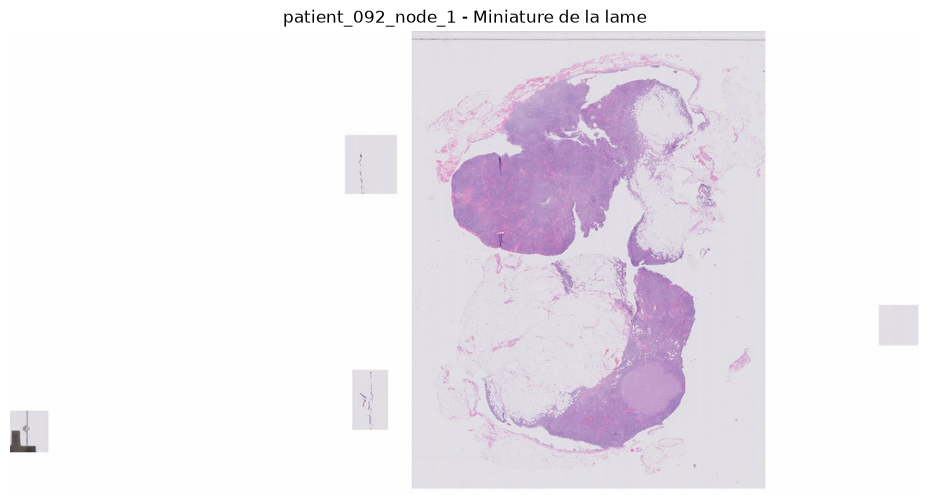

In [32]:
# On affiche une miniature de la lame

# get_thumbnail fabrique une petite image de toute la lame, on lui demande au plus 1000 px de large ou de haut
miniature_lame = lame.get_thumbnail((1000, 1000))
# .size donne (largeur, hauteur) de l'image PIL
print("Taille de la miniature :", miniature_lame.size)

# On crée une figure de 12 × 6 pouces
plt.figure(figsize=(12, 6))
# On y affiche l'image
plt.imshow(miniature_lame)
# On cache les axes gradués
plt.axis("off")
plt.title("patient_092_node_1 - Miniature de la lame")
plt.show()

In [33]:
# On compare la taille de la lame et celle de son masque

lame = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, "patient_092_node_1.tif"))
masque = openslide.OpenSlide(os.path.join(DOSSIER_MASQUES, "patient_092_node_1_mask.tif"))

# On fait la même chose pour les deux fichiers avec une boucle sur des couples (nom, objet)
for nom, image in [("Lame", lame), ("Masque", masque)]:
    # Les dimensions au niveau 0
    largeur, hauteur = image.level_dimensions[0]
    # .get() renvoie la propriété (ou None si elle n'existe pas, sans erreur)
    print(f"{nom} : niveau 0 = {largeur} x {hauteur} pixels, "
          f"{image.properties.get('openslide.mpp-x')} µm par pixel, "
          f"{image.level_count} niveaux")

Lame : niveau 0 = 184320 x 93696 pixels, 0.25 µm par pixel, 10 niveaux
Masque : niveau 0 = 184320 x 93696 pixels, 0.25 µm par pixel, 10 niveaux


> Les masques ont donc la même taille que les lames au niveau 0 et la même taille de pixels ! On pourra donc les utiliser plutôt que les annotations (cf note en partie 5.1.1.) car la résolution est précise.

Taille de la miniature : (1000, 508)


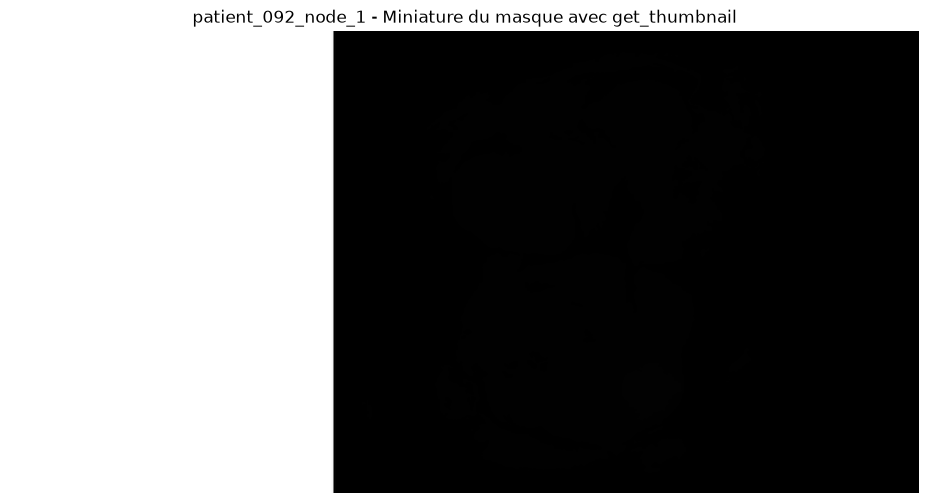

In [34]:
# On essaie d'afficher le masque avec get_thumbnail (mais ne marche pas bien)

masque = openslide.OpenSlide(os.path.join(DOSSIER_MASQUES, "patient_092_node_1_mask.tif"))
# Miniature du masque, max 1000 px
miniature_masque_get_thumbnail = masque.get_thumbnail((1000, 1000))
print("Taille de la miniature :", miniature_masque_get_thumbnail.size)

plt.figure(figsize=(12, 6))
plt.imshow(miniature_masque_get_thumbnail)
plt.axis("off")
plt.title("patient_092_node_1 - Miniature du masque avec get_thumbnail")
plt.show()

In [35]:
# On regarde les valeurs présentes dans la miniature du masque

# np.array transforme l'image en tableau de nombres
valeurs_miniature_masque = np.array(miniature_masque_get_thumbnail)
# On affiche la shape du tableau NumPy obtenu (lignes, colonnes, canaux)
print(valeurs_miniature_masque.shape)
# np.unique donne la liste des valeurs différentes
print(np.unique(valeurs_miniature_masque))

(508, 1000, 3)
[  0   1   2   6 143 250 255]


On ne peut pas utiliser get_thumbnail tel quel pour les masques car :
- Pour une image classique, comme pour une lame ici, chaque pixel a trois valeurs (RGB, entre 0 et 255) correspondant aux trois canaux de l'image.
- Pour le masque, chaque pixel a ici une seule valeur : 0 (le fond), 1 (le tissu sain) ou 2 (la zone tumorale). Matplotlib affiche les valeurs sur une échelle de 0 à 255 donc 0, 1 et 2 apparaissent tous presque noirs. On pourrait le corriger en choisissant nos couleurs. Le problème est que get_thumbnail remplace les zones vides avec du blanc et fait la moyenne des pixels voisins donc on obtient des valeurs en dehors et 0, 1 et 2.

On va donc utiliser read_region qui ne fait pas ces "retouches" de get_thumbnail. On peut choisir un morceau de l'image si on le veut (get_thumbnail prend toute l'image), on choisit nous-même le niveau et on doit indiquer la taille exacte (pas la max).

In [36]:
# On lit la lame et le masque avec read_region, qui garde les vraies valeurs

# On lit au niveau 7 (car plus rapide)
niveau = 7
# Taille voulue = toute la largeur et la hauteur du niveau 7
taille = masque.level_dimensions[niveau]

# read_region(position du coin en haut à gauche au niveau 0, niveau lu, taille au niveau lu)
region_lame = lame.read_region((0, 0), niveau, taille)
region_masque = masque.read_region((0, 0), niveau, taille)

# En tableau on obtient (hauteur, largeur, 4 canaux RGBA)
valeurs_lame = np.array(region_lame)
# Pour le masque on ne garde que le canal 0 qui contient 0, 1 ou 2 ([:, :, 0] = toutes les lignes, toutes les colonnes, canal 0)
valeurs_masque = np.array(region_masque)[:, :, 0]

# On vérifie : OpenSlide donne (largeur, hauteur) vs NumPy (hauteur, largeur) d'où l'inversion
print("Taille lue au niveau", niveau, ":", taille)
print("Forme du tableau de la lame :", valeurs_lame.shape)
print("Forme du tableau du masque :", valeurs_masque.shape)
# Cette fois, seulement 0, 1 et 2
print("Valeurs présentes dans le masque :", np.unique(valeurs_masque))

Taille lue au niveau 7 : (1440, 732)
Forme du tableau de la lame : (732, 1440, 4)
Forme du tableau du masque : (732, 1440)
Valeurs présentes dans le masque : [0 1 2]


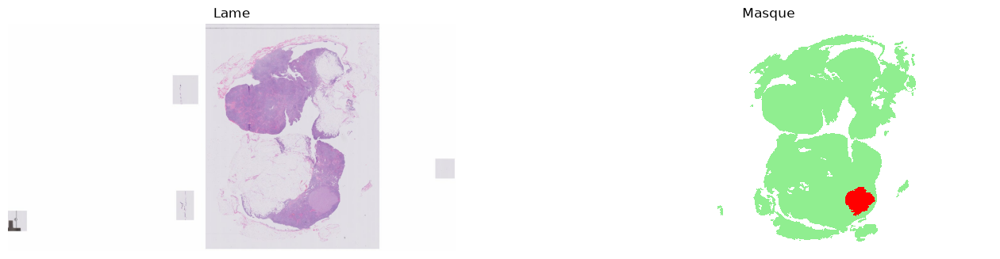

In [37]:
# On affiche la lame et le masque côte à côte avec nos couleurs

# On liste les couleurs à utiliser pour 0 (fond) 1 (sain) et 2 (tumeur)
couleurs = ListedColormap(["white", "lightgreen", "red"])

# Une figure avec 1 ligne et 2 graphiques
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# À gauche la lame
axes[0].imshow(valeurs_lame)
axes[0].set_title(f"Lame")
axes[0].axis("off")

# À droite le masque
# vmin=0 et vmax=2 fixent l'échelle pour que 0, 1 et 2 prennent bien nos 3 couleurs
# interpolation="nearest" garde les pixels nets (pas de mélange entre voisins comme avec get_thumbnail)
axes[1].imshow(valeurs_masque, cmap=couleurs, vmin=0, vmax=2, interpolation="nearest")
axes[1].set_title("Masque")
axes[1].axis("off")

plt.show()

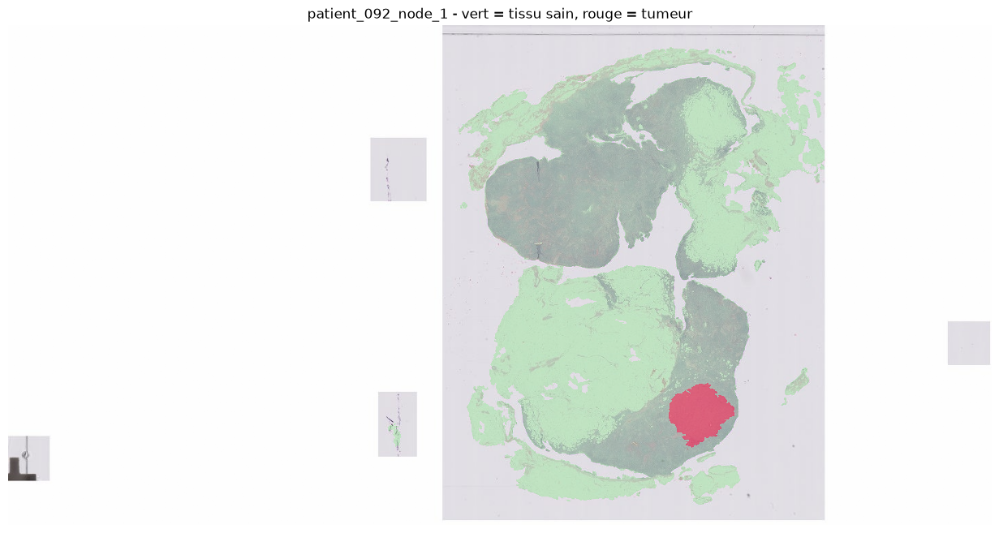

In [38]:
# On superpose le masque à la lame (avec un fond transparent)

# On cache les pixels qui valent 0 pour voir la lame à travers
tissu_et_tumeur = np.ma.masked_where(valeurs_masque == 0, valeurs_masque)

plt.figure(figsize=(16, 8))
# La lame
plt.imshow(valeurs_lame)
# Puis le masque par-dessus (vert pour 1, rouge pour 2, alpha=0.4=transparent à 60 %)
plt.imshow(tissu_et_tumeur, cmap=ListedColormap(["lightgreen", "red"]),
           vmin=1, vmax=2, alpha=0.4, interpolation="nearest")
plt.axis("off")
plt.title("patient_092_node_1 - vert = tissu sain, rouge = tumeur")
plt.show()

#### 5.1.3. Découper les lames en patchs

**Pourquoi faut-il découper les lames en patchs ?**

- L'image est beaucoup trop grande (pas possible avec les CNN)
- Si on réduisait l'image pour pouvoir utiliser un CNN, on perdrait le détail qui nous permet de voir les cellules tumorales
- Il y aurait trop peu d'exemples pour le modèle si on le faisait tourner sur les lames entières (une lame = une étiquette et l'étiquette ne dit pas où est la tumeur). C'est beaucoup plus précis avec les patchs.

**Les questions à se poser**

1. **Quelle surface choisir ? A quel niveau découper ? Quelle taille de patch choisir ?**
- Surface choisie : environ 100 à 200 µm soit assez pour voir un amas de cellules mais assez petit pour repérer les ITC
- Niveau 1 (0,5 µm par pixel) car une cellule tumorale y fait environ 20 pixels et c’est 4 fois moins coûteux que le niveau 0
- Taille de patch de 224 × 224 pixels (112 µm), soit exactement la taille des images d'entraînement de ResNet18 (224 pixels).

2. **Quel pas ?**
- 224 px sans chevauchement, pour l’entraînement et la validation. Pour l'analyse des lames entières on utilisera 112 px avec 50 % de chevauchement. Pourquoi ? Pour chaque patch d'entrainement on regarde le masque et on le classe tumoral si tumeur au centre du patch, sain si rien dans tout le patch et on l'écarte s'il y a de la tumeur sur le bord (cf ci-dessous). Donc le modèle classe en fonction de la zone centrale du patch. Donc pour analyser des lames entière on prend un pas de 112 px ce qui permet que toute celulle se retrouve toujours dans la zone centrale d'un patch. 

3. **Comment repérer le tissu ?**
- Par les couleurs (plus précisément la saturation) pour toutes les lames. Le masque sert seulement aux étiquettes et à vérifier la détection. L'idée est de pouvoir utiliser la même méthode en entrainement et test (or en test on aura pas les masques pour repérer le tissu.)

4. **Uniformiser les couleurs des patchs (différences entre centres)?**
- Prototype : non car un seul centre pour le prototype.

5. **Combien de tissu minimum par patch ?**
- Au moins 25 % mesuré sur le patch entier avec la même règle pour tous les patchs (règle simple pour le prototype).

6. **Comment étiqueter un patch ?**
- Tumoral s’il y a de la tumeur dans la zone centrale (112 × 112 px) et sain s’il n’y a aucune tumeur dans le patch, écarté sinon. Le modèle apprendra donc à détecter ce qu'il y a dans la zone centrale du patch et avec notre carte de chaleur on utilisera un pas pour s'assurer que toute partie de la lame est couverte par la zone centrale d'un patch (donc on prendra un pas correspondant à la taille du patch / 2) Les autres options auraient été de choisir de mettre en tumoral un patch dès qu'il y a rien qu'une seule cellule tumorale dedans mais le modèle apprendrait "tumoral" pour un patch sain à 98%... La dernière option aurait été de choisir l'étiquette en fonction d'un certain pourcentage de surface avec cellules tumorales dans le patch mais donc le modèle pourrait apprendre qu'un patch avec une ITC est "sain"...

7. **Quel équilibre entre les classes ?**
- On choisit de chercher un équilibre proche de 50/50 donc on va sous-échantillonner les patchs sains : on prendra tous les patchs tumoraux et autant de patchs sains répartis entre les 3 lames d’entraînement. Pour la solution finale il faudra se reposer la question car la majorité des erreurs que nous avons vient des patchs sains qui sont prédits tumoraux donc il faut que le modèle soit bien entrainé à reconnaitre les tissus sains. **On testera plusieurs méthodes : 50/50 ou 25/75 par exemple pour voir ce qui donne les meilleures performances (si déséquilibre on utilisera class_weight="balanced").

8. **Comment enregistrer ?**
- Un tableau CSV et des PNG pour l’entraînement et la validation. Pour les lames entières, on lit les patchs à la volée et on enregistre seulement les prédictions.

In [39]:
# On regroupe tous les réglages du découpage en patchs (en majuscules = constantes)

# Niveau de lecture des patchs (0,5 µm par pixel)
NIVEAU_PATCH = 1
# Côté du patch en pixels (224 px × 0,5 µm = 112 µm)
TAILLE_PATCH = 224
# Pas pour les patchs d'entraînement et de validation (= taille = sans chevauchement)
PAS_ENTRAINEMENT = 224
# Largeur de la zone centrale qui décide de l'étiquette
TAILLE_CENTRE = 112
# Niveau réduit (8 µm par pixel) pour détecter le tissu rapidement
NIVEAU_TISSU = 5
# Saturation minimale d'un pixel pour être considéré comme du tissu
SEUIL_SATURATION = 0.04
# Part minimale de tissu dans un patch (25 %)
SEUIL_TISSU = 0.25
# Graine aléatoire pour les tirages (pour retrouver exactement les mêmes patchs à chaque fois)
GRAINE = 42
# Nombre maximal de patchs tumoraux par lame (pour qu'une grosse tumeur ne fournisse pas tous les exemples)
QUOTA_TUMORAL = 1000

In [40]:
# On crée une fonction pour lire une région de la lame en RGB, avec du blanc à la place du transparent

def lire_rgb(lame, position, niveau, taille):
    """Lit une région avec read_region et remplace les zones transparentes par du blanc."""
    # read_region renvoie une image RGBA (le canal A vaut 0 dans les zones non numérisées)
    region = lame.read_region(position, niveau, taille)
    # On crée une image blanche de la même taille, en RGB
    image = Image.new("RGB", region.size, (255, 255, 255))
    # region.split() sépare l'image en ses 4 canaux (R, G, B, A) et [3] prend le canal A.
    # paste colle region sur l'image blanche et mask dit, pixel par pixel, si on colle :
    # si A vaut 0 (transparent), on ne colle rien et le blanc reste
    image.paste(region, mask=region.split()[3])
    # On renvoie l'image RGB
    return image

read_region renvoie une image RGBA et on a besoin de la convertir en RGB pour le modèle (c'est ce qu'il attend). Or, si on la convertit directement en RGB, les zones transparentes (donc non numérisées) deviennent noires car un pixel vide = (0,0,0,0) et donc en RGA (0,0,0). 
Cette fonction crée une image blanche puis colle la région par-dessus. Ainsi, les zones transparentes restent blanches.

In [41]:
# On crée une fonction qui détecte le tissu par la couleur (saturation)

def masque_tissu(lame, niveau=NIVEAU_TISSU, seuil=SEUIL_SATURATION):
    """Renvoie un tableau de booléens : True là où il y a du tissu (saturation au-dessus du seuil)."""
    # On lit toute la lame au niveau 5 et on la met en tableau NumPy (hauteur, largeur, 4 canaux, valeurs 0 à 255)
    region = np.array(lame.read_region((0, 0), niveau, lame.level_dimensions[niveau]))
    # On garde R, G et B ([:, :, :3] = les canaux 0, 1, 2) et .copy() pour pouvoir modifier sans toucher à region
    rgb = region[:, :, :3].copy()
    # Les pixels transparents (canal A == 0) deviennent blancs : on met 255 dans les trois canaux
    rgb[region[:, :, 3] == 0] = 255
    # On convertit en HSV (teinte, saturation, luminosité) pour avoir la saturation
    hsv = np.array(Image.fromarray(rgb).convert("HSV"))
    # Le canal 1 est la saturation, entre 0 et 255 : on divise par 255 pour l'avoir entre 0 et 1
    saturation = hsv[:, :, 1] / 255
    # saturation > seuil donne un tableau de True/False : c'est notre masque de tissu
    return saturation > seuil

On lit toute la lame au niveau 5 pour que ce soit plus rapide qu'à un niveau inférieur et c'est suffisant pour détecter le tissu.

Part de la lame détectée comme tissu (couleurs) : 0.141
Part de la lame en tissu selon le masque officiel : 0.203
Part du tissu officiel retrouvée par notre détection : 0.68
Part de notre tissu qui est aussi du tissu officiel : 0.978


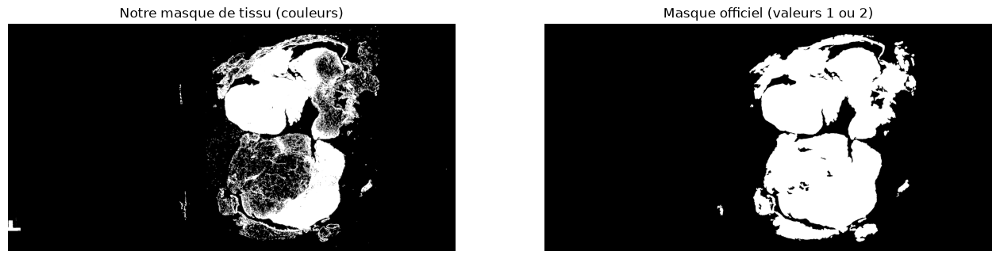

In [42]:
# On compare notre détection du tissu au masque officiel

masque = openslide.OpenSlide(os.path.join(DOSSIER_MASQUES, "patient_092_node_1_mask.tif"))
# Le masque officiel au même niveau 5 que notre détection, canal 0 (0, 1 ou 2)
masque_reduit = np.array(masque.read_region((0, 0), NIVEAU_TISSU, masque.level_dimensions[NIVEAU_TISSU]))[:, :, 0]

# Notre détection : True pour le tissu, False pour le fond
tissu = masque_tissu(lame)
# Le tissu selon le masque officiel : tout ce qui n'est pas du fond (1 ou 2)
tissu_officiel = masque_reduit > 0

# .mean() sur des True/False donne la part de True
print("Part de la lame détectée comme tissu (couleurs) :", round(tissu.mean(), 3))
print("Part de la lame en tissu selon le masque officiel :", round(tissu_officiel.mean(), 3))
# Parmi le tissu officiel, quelle part avons-nous trouvée ? (& = les deux à la fois)
print("Part du tissu officiel retrouvée par notre détection :", round((tissu & tissu_officiel).sum() / tissu_officiel.sum(), 3))
# Parmi ce que nous avons détecté, quelle part est vraiment du tissu ?
print("Part de notre tissu qui est aussi du tissu officiel :", round((tissu & tissu_officiel).sum() / tissu.sum(), 3))

# On affiche les deux masques côte à côte, en noir et blanc
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].imshow(tissu, cmap="gray")
axes[0].set_title("Notre masque de tissu (couleurs)")
axes[0].axis("off")
axes[1].imshow(tissu_officiel, cmap="gray")
axes[1].set_title("Masque officiel (valeurs 1 ou 2)")
axes[1].axis("off")
plt.show()

Résultats sur la lame 092 : 
- 98 % de ce qu’on détecte est bien du tissu (presque aucune fausse détection) et on retrouve 68 % du tissu officiel. 
- Ce qu’on manque ce sont surtout des zones très pâles que le masque officiel compte comme tissu mais ce n’est pas gênant car aucun patch tumoral n’est perdu (voir plus bas).
- Par contre on voit ici qu'on a pris un petit bout en bas à gauche alors que ce n'est pas du tissu. Ca ajoute quelques faux patchs sains.

In [43]:
# On crée une fonction qui parcourt la lame patch par patch et note chaque patch avec du tissu :
# - si le patch n'a pas du tout de tissu, il est ignoré
# - sinon, on regarde dans le masque s'il y a de la tumeur pour l'étiqueter (tumoral, sain ou écarté)

def lister_patchs(nom_lame, nom_set, pas=PAS_ENTRAINEMENT):
    """Parcourt la lame sur une grille et renvoie un tableau des patchs qui contiennent du tissu."""
    # On ouvre la lame et son masque
    lame = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, nom_lame + ".tif"))
    masque = openslide.OpenSlide(os.path.join(DOSSIER_MASQUES, nom_lame + "_mask.tif"))
    # Notre masque de tissu au niveau 5
    tissu = masque_tissu(lame)

    # De combien le niveau 1 est réduit par rapport au niveau 0 (2), car read_region attend ses positions au niveau 0
    facteur_patch = int(lame.level_downsamples[NIVEAU_PATCH])
    # Idem pour le niveau 5 (32)
    facteur_tissu = int(lame.level_downsamples[NIVEAU_TISSU])
    # Le côté du patch en pixels du niveau 0 (224 × 2 = 448)
    taille_0 = TAILLE_PATCH * facteur_patch
    # Le pas en pixels du niveau 0
    pas_0 = pas * facteur_patch
    # Où commence la zone centrale dans le patch ((224 - 112) // 2 = 56 ; // = division entière)
    debut_centre = (TAILLE_PATCH - TAILLE_CENTRE) // 2
    # Où elle finit (56 + 112 = 168)
    fin_centre = debut_centre + TAILLE_CENTRE
    # Les dimensions de la lame au niveau 0
    largeur_0, hauteur_0 = lame.dimensions

    # Liste qui contiendra une ligne (un dictionnaire) par patch
    patchs = []
    # On parcourt chaque "ligne" de patchs de haut en bas (de 0 jusqu'au dernier patch complet, en avançant du pas).
    # A noter : un patch incomplet en fin de ligne est ignoré
    for y in range(0, hauteur_0 - taille_0 + 1, pas_0):
        # Et pour chaque ligne, chaque colonne de gauche à droite
        for x in range(0, largeur_0 - taille_0 + 1, pas_0):
            # Le patch va de x à x + 448 et de y à y + 448 au niveau 0. Pour trouver le même carré dans tissu
            # (niveau 5), on divise ses 4 bords par 32 : on obtient un petit tableau de 14 × 14 True/False
            zone_tissu = tissu[y // facteur_tissu:(y + taille_0) // facteur_tissu,
                               x // facteur_tissu:(x + taille_0) // facteur_tissu]
            # La part de tissu dans le carré
            pct_tissu = zone_tissu.mean()
            # Pas de tissu du tout : on passe directement au patch suivant (continue)
            if pct_tissu == 0:
                continue

            # On lit le même carré dans le masque officiel, au niveau 1, canal 0 (0, 1 ou 2)
            zone_masque = np.array(masque.read_region((x, y), NIVEAU_PATCH, (TAILLE_PATCH, TAILLE_PATCH)))[:, :, 0]
            # La part de pixels tumoraux dans tout le patch
            pct_tumeur = (zone_masque == 2).mean()
            # La part de pixels tumoraux dans la zone centrale seulement
            pct_tumeur_centre = (zone_masque[debut_centre:fin_centre, debut_centre:fin_centre] == 2).mean()

            # Etiquette : tumoral si de la tumeur au centre
            if pct_tumeur_centre > 0:
                etiquette = "tumoral"
            # sain si aucune tumeur dans tout le patch
            elif pct_tumeur == 0:
                etiquette = "sain"
            # écarté sinon (tumeur seulement sur le bord : cas ambigu pour l'entraînement)
            else:
                etiquette = "ecarte"

            # On ajoute la ligne du patch (position, pourcentages, assez de tissu ou non, étiquette)
            patchs.append({
                "lame": nom_lame, "set": nom_set, "x": x, "y": y, "niveau": NIVEAU_PATCH,
                "pct_tissu": round(pct_tissu, 3), "pct_tumeur": round(pct_tumeur, 4),
                "pct_tumeur_centre": round(pct_tumeur_centre, 4),
                "assez_de_tissu": pct_tissu >= SEUIL_TISSU, "etiquette": etiquette,
            })
    # On transforme la liste en DataFrame
    return pd.DataFrame(patchs)

In [44]:
# On applique lister_patchs aux lames d'entraînement et de validation

# On relit la sélection des lames
selection = pd.read_csv("../data/prototype/selection_lames_prototype.csv")
# On ne garde que les lames d'entraînement et de validation (pas le test)
lames_patchs = selection[selection["set"].isin(["entrainement", "validation"])]

# Liste qui contiendra un DataFrame par lame
tableaux = []
for _, ligne in lames_patchs.iterrows():
    # L'heure au début du traitement de la lame
    debut = time.time()
    # Le DataFrame des patchs de cette lame
    tableau = lister_patchs(ligne["lame"], ligne["set"])
    # On l'ajoute à la liste
    tableaux.append(tableau)
    # time.time() - debut = durée en secondes
    print(f"{ligne['lame']} : {len(tableau)} patchs avec du tissu ({time.time() - debut:.0f} s)")

# On empile tous les DataFrames en un seul (ignore_index=True : on renumérote les lignes)
candidats = pd.concat(tableaux, ignore_index=True)

patient_089_node_3 : 10006 patchs avec du tissu (15 s)
patient_096_node_0 : 21732 patchs avec du tissu (31 s)
patient_083_node_4 : 3952 patchs avec du tissu (7 s)
patient_092_node_1 : 18663 patchs avec du tissu (28 s)


In [45]:
# On sépare les patchs utilisables des patchs écartés et on compte

# True pour les patchs avec moins de 25 % de tissu (~ = "non")
peu_de_tissu = ~candidats["assez_de_tissu"]
# True pour les patchs ambigus (tumeur seulement sur le bord)
ambigu = candidats["etiquette"] == "ecarte"
# Les écartés : peu de tissu OU ambigus (| = "ou")
ecartes = candidats[peu_de_tissu | ambigu].copy()
# Les utilisables : ni l'un ni l'autre
utilisables = candidats[~peu_de_tissu & ~ambigu]

# On note la raison de l'écart : "ambigu" par défaut...
ecartes["raison"] = "ambigu"
# ... puis "peu de tissu" pour ceux qui n'ont pas assez de tissu (.loc[lignes, colonne] = valeur)
ecartes.loc[~ecartes["assez_de_tissu"], "raison"] = "peu de tissu"

# crosstab compte les patchs par (ensemble, lame) en lignes et par étiquette en colonnes, margins=True ajoute les totaux
print("Patchs utilisables :")
display(pd.crosstab([utilisables["set"], utilisables["lame"]], utilisables["etiquette"], margins=True))

print("Patchs écartés :")
display(pd.crosstab([ecartes["set"], ecartes["lame"]], ecartes["raison"], margins=True))

# Les patchs tumoraux qu'on aurait perdus à cause du seuil de tissu (on espère 0)
perdus = ecartes[(ecartes["raison"] == "peu de tissu") & (ecartes["etiquette"] == "tumoral")]
print("Patchs tumoraux écartés par le seuil de tissu :", len(perdus))

Patchs utilisables :


etiquette                         sain  tumoral    All
set          lame                                     
entrainement patient_083_node_4   3732        0   3732
             patient_089_node_3   8465        6   8471
             patient_096_node_0   9614    10056  19670
validation   patient_092_node_1  14084      501  14585
All                              35895    10563  46458

Patchs écartés :


raison                           ambigu  peu de tissu   All
set          lame                                          
entrainement patient_083_node_4       0           220   220
             patient_089_node_3      10          1525  1535
             patient_096_node_0     242          1820  2062
validation   patient_092_node_1      28          4050  4078
All                                 280          7615  7895

Patchs tumoraux écartés par le seuil de tissu : 0


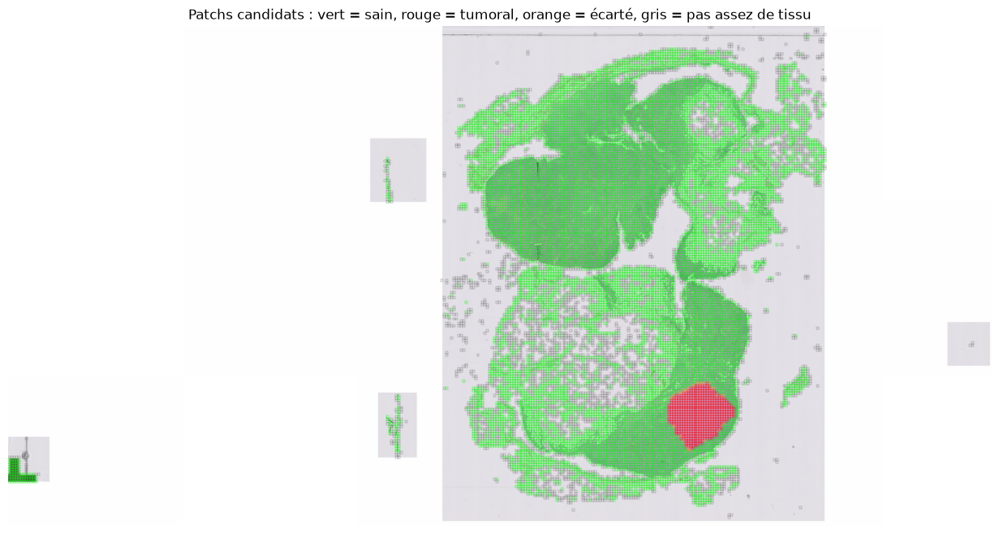

In [46]:
# On dessine les patchs candidats sur la lame pour vérifier (exemple avec la 092)

nom_lame = "patient_092_node_1"
lame = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, nom_lame + ".tif"))
# Juste pour l'affichage, donc un niveau élevé (petite image)
niveau_vue = 6
# La lame entière au niveau 6, avec du blanc à la place du transparent
vue = lire_rgb(lame, (0, 0), niveau_vue, lame.level_dimensions[niveau_vue])
# De combien le niveau 6 est réduit par rapport au niveau 0 (64)
facteur_vue = lame.level_downsamples[niveau_vue]
# La taille d'un patch sur cette image : 224 px au niveau 1 = 448 au niveau 0 = 448 / 64 = 7 px au niveau 6
taille_vue = TAILLE_PATCH * lame.level_downsamples[NIVEAU_PATCH] / facteur_vue
# Une couleur par étiquette (un dictionnaire)
couleurs = {"sain": "lime", "tumoral": "red", "ecarte": "orange"}

fig, ax = plt.subplots(figsize=(16, 8))
ax.imshow(vue)
# Pour chaque patch candidat de cette lame
for _, p in candidats[candidats["lame"] == nom_lame].iterrows():
    # La couleur de son étiquette, ou gris s'il n'a pas assez de tissu (condition sur une ligne : A if condition else B)
    couleur = couleurs[p["etiquette"]] if p["assez_de_tissu"] else "gray"
    # On dessine un carré vide : position = coin du patch divisé par 64 (repère du niveau 6)
    ax.add_patch(Rectangle((p["x"] / facteur_vue, p["y"] / facteur_vue), taille_vue, taille_vue,
                           fill=False, edgecolor=couleur, linewidth=0.3))
ax.set_title("Patchs candidats : vert = sain, rouge = tumoral, orange = écarté, gris = pas assez de tissu")
ax.axis("off")
plt.show()

In [47]:
# On choisit les patchs gardés (50 % sains, 50 % tumoraux, quota par lame)

# Liste qui contiendra les patchs choisis, un DataFrame par paquet choisi
morceaux = []
# On fait la même chose pour l'entraînement et pour la validation
for nom_set in ["entrainement", "validation"]:
    # Les patchs utilisables de cet ensemble
    patchs_set = utilisables[utilisables["set"] == nom_set]
    # La liste de ses lames (.unique() = sans doublons)
    lames_set = patchs_set["lame"].unique()

    # On prend les patchs tumoraux de chaque lame, dans la limite du quota (1000)
    nb_tumoraux = 0
    for nom_lame in lames_set:
        # Tous les patchs tumoraux de la lame
        tumoraux_lame = patchs_set[(patchs_set["lame"] == nom_lame) & (patchs_set["etiquette"] == "tumoral")]
        # On en tire au hasard 1000 s'il y en a plus (sinon on les prend tous), random_state = graine fixe
        choisis = tumoraux_lame.sample(n=min(len(tumoraux_lame), QUOTA_TUMORAL), random_state=GRAINE)
        # On les ajoute à la liste
        morceaux.append(choisis)
        # On compte combien on en a pris au total
        nb_tumoraux += len(choisis)

    # On prend autant de sains que de tumoraux, répartis à parts égales entre les lames
    nb_sains_par_lame = nb_tumoraux // len(lames_set)
    for nom_lame in lames_set:
        # Tous les patchs sains de la lame
        sains_lame = patchs_set[(patchs_set["lame"] == nom_lame) & (patchs_set["etiquette"] == "sain")]
        # On en tire au hasard la part de la lame
        choisis = sains_lame.sample(n=min(len(sains_lame), nb_sains_par_lame), random_state=GRAINE)
        morceaux.append(choisis)

# On empile tous les morceaux dans un seul DataFrame
echantillon = pd.concat(morceaux, ignore_index=True)

# On vérifie les nombres par ensemble, lame et étiquette
display(pd.crosstab([echantillon["set"], echantillon["lame"]], echantillon["etiquette"], margins=True))

etiquette                        sain  tumoral   All
set          lame                                   
entrainement patient_083_node_4   335        0   335
             patient_089_node_3   335        6   341
             patient_096_node_0   335     1000  1335
validation   patient_092_node_1   501      501  1002
All                              1506     1507  3013

In [48]:
# On enregistre chaque patch choisi en image PNG et le tableau en CSV

os.makedirs("../data/prototype/patchs", exist_ok=True)
DOSSIER_PATCHS = "../data/prototype/patchs"

debut = time.time()
# Pour chaque lame (on ne l'ouvre qu'une fois)
for nom_lame in echantillon["lame"].unique():
    lame = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, nom_lame + ".tif"))
    # Les patchs choisis de cette lame
    patchs_lame = echantillon[echantillon["lame"] == nom_lame]
    # On parcourt les patchs (index = le numéro de la ligne dans echantillon, qu'on réutilise plus bas)
    for index, p in patchs_lame.iterrows():
        # Le dossier de destination : patchs/ensemble/étiquette
        dossier = os.path.join(DOSSIER_PATCHS, p["set"], p["etiquette"])
        # On crée le dossier s'il n'existe pas
        os.makedirs(dossier, exist_ok=True)
        # Le nom du fichier, construit avec la lame et la position du patch
        nom_fichier = f"{nom_lame}_x{p['x']}_y{p['y']}.png"
        # On découpe le patch dans la lame (int() car OpenSlide veut des entiers Python)
        image = lire_rgb(lame, (int(p["x"]), int(p["y"])), NIVEAU_PATCH, (TAILLE_PATCH, TAILLE_PATCH))
        # On l'enregistre
        image.save(os.path.join(dossier, nom_fichier))
        # On note dans le df, sur la ligne du patch, où l'image est enregistrée
        echantillon.loc[index, "fichier"] = os.path.join(p["set"], p["etiquette"], nom_fichier)
    print(f"{nom_lame} : {len(patchs_lame)} patchs enregistrés")

# On enregistre le tableau en CSV
echantillon.to_csv(os.path.join(DOSSIER_PATCHS, "patchs.csv"), index=False)

print(f"Terminé en {time.time() - debut:.0f} s")

patient_089_node_3 : 341 patchs enregistrés
patient_096_node_0 : 1335 patchs enregistrés
patient_083_node_4 : 335 patchs enregistrés
patient_092_node_1 : 1002 patchs enregistrés
Terminé en 34 s


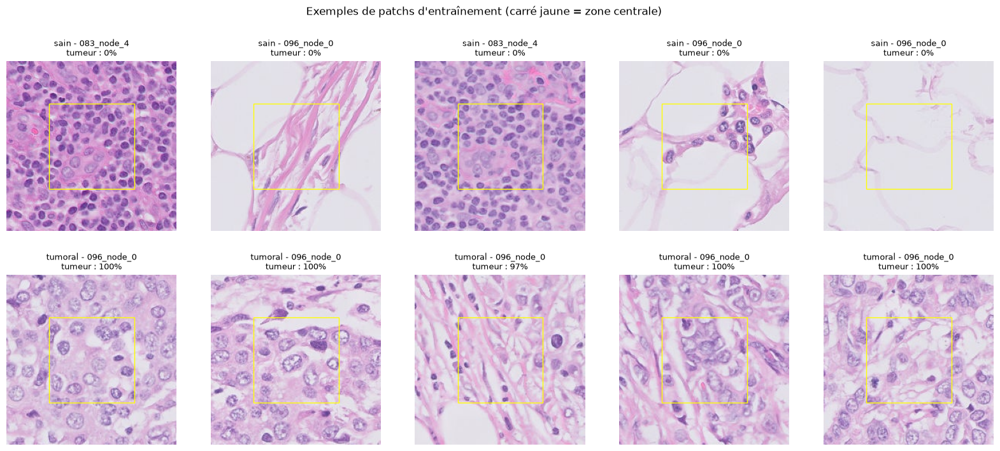

In [49]:
# On affiche quelques patchs de chaque classe pour vérifier à l'oeil

# Une grille de 2 lignes (sains, tumoraux) et 5 colonnes
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
# Où commence la zone centrale (56 px)
debut_centre = (TAILLE_PATCH - TAILLE_CENTRE) // 2
# enumerate donne le numéro (i = 0 puis 1) et l'étiquette
for i, etiquette in enumerate(["sain", "tumoral"]):
    # 5 patchs d'entraînement de cette étiquette, tirés au hasard
    exemples = echantillon[(echantillon["set"] == "entrainement") & (echantillon["etiquette"] == etiquette)].sample(n=5, random_state=GRAINE)
    # j = numéro de la colonne, p = la ligne du patch
    for j, (_, p) in enumerate(exemples.iterrows()):
        # On ouvre le PNG
        image = Image.open(os.path.join(DOSSIER_PATCHS, p["fichier"]))
        axes[i, j].imshow(image)
        # On dessine la zone centrale en jaune
        axes[i, j].add_patch(Rectangle((debut_centre, debut_centre), TAILLE_CENTRE, TAILLE_CENTRE,
                                       fill=False, edgecolor="yellow", linewidth=1))
        # Titre : étiquette, lame (sans "patient_" grâce à [8:]) et part de tumeur (:.0% = en pourcentage)
        axes[i, j].set_title(f"{etiquette} - {p['lame'][8:]}\ntumeur : {p['pct_tumeur']:.0%}", fontsize=9)
        axes[i, j].axis("off")
plt.suptitle("Exemples de patchs d'entraînement (carré jaune = zone centrale)")
plt.show()

#### 5.1.4. Entrainement du modèle de patchs

In [50]:
# On choisit où faire les calculs et on relit le tableau des patchs

# appareil : où pytorch doit faire les calculs
# "xpu" = la carte graphique Intel si PyTorch la trouve (plus rapide) sinon le processeur ("cpu")
appareil = "xpu" if torch.xpu.is_available() else "cpu"
print("Calculs sur :", appareil)

# On relit le tableau des patchs enregistrés
patchs = pd.read_csv(os.path.join(DOSSIER_PATCHS, "patchs.csv"))
# On compte les patchs par ensemble et par étiquette
print(patchs.groupby(["set", "etiquette"]).size())

Calculs sur : xpu
set           etiquette
entrainement  sain         1005
              tumoral      1006
validation    sain          501
              tumoral       501
dtype: int64


In [51]:
# On définit la préparation appliquée à chaque patch avant de le donner au réseau

# transforms permet de faire des transformations sur les images (de la biblio Torchvision = biblio d'outils d'images qui accompagne PyTorch)
# Compose enchaîne les transformations dans l'ordre
preparation = transforms.Compose([
    # ToTensor transforme les images (hauteur, largeur, canaux) en tenseurs Pytorch (canaux, hauteur, largeur) et les valeurs de 0-255 à 0-1
    transforms.ToTensor(),
    # Normalize normalise retire la moyenne et on divise par l'écart-type d'ImageNet, canal par canal (R, G, B),
    # pour présenter nos patchs comme les images sur lesquelles ResNet18 a appris
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

On définit ici les étapes qu'on appliquera sur chaque patch :
- .ToTensor() pour transformer l'image en tenseur PyTorch en faisant deux changements :
    - L'ordre des dimensions : on a (hauteur, largeur, canaux) pour les images et PyTorch veut (canaux, hauteur, largeur)
    - Les valeurs passent de 0-255 à 0-1 (les réseaux fonctionnent mieux avec des petites valeurs)
- .Normalize() pour normaliser les valeurs sur chaque canal : (valeur - moyenne du canal) / écart-type du canal calculé sur les photos d'ImageNet (base de ResNet18 : https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html). On obtient des valeurs centrées autour de 0. On utilise les valeurs utilisées pour ResNet18 pour appliquer exactement la même normalisation. On a ainsi des valeurs centrées autour de 0 et étalées de la même façon pour chaque canal. Cela rend l'apprentissage par descente de gradient plus stable et plus rapide. Et surtout, encore une fois, on a ainsi la même chose que ce qu'avait le modèle pour son entrainement et ses filtres reçoivent ainsi des nombres ressemblants à ceux pour lesquels ils ont été réglés.

Donc on standardise pour avoir des petites valeurs, toutes la même échelle, et pour avoir des valeurs centrées sur 0 (mieux pour le modèle qui apprend plus vite et est plus stable).

A noter : preparation sera appelé avec des images PIL (objets python en mémoire vive), pas TIFF ou PNG (c'est le format des fichiers sur le disque) ni des arrays Numpy (on aurait pu).
Rappel :
- Les lames sont ouvertes avec OpenSlide (trop grandes pour être ouvertes avec Image.open()) et on en prend une partie avec read_region qui renvoie une image PIL
- Les patchs PNG sont lus avec Image.open() qui renvoie une image PIL

In [52]:
# On écrit notre propre Dataset qui explique à PyTorch comment lire un patch

# On hérite de la classe Dataset de PyTorch (on remplit son "formulaire")
class PatchsDataset(Dataset):
    """Lit les patchs PNG listés dans un tableau et renvoie (image préparée, étiquette)."""

    # Appelée quand on crée l'objet : on garde le tableau, le dossier et la préparation
    def __init__(self, tableau, dossier, transformation):
        # On renumérote les lignes de 0 à n-1 pour pouvoir y accéder par numéro
        self.tableau = tableau.reset_index(drop=True)
        self.dossier = dossier
        self.transformation = transformation

    # Question 1 de PyTorch : combien de données ?
    def __len__(self):
        return len(self.tableau)

    # Question 2 de PyTorch : comment obtenir la donnée numéro i ?
    def __getitem__(self, i):
        # La ligne numéro i du tableau
        ligne = self.tableau.iloc[i]
        # On ouvre le PNG et on s'assure qu'il est en RGB
        image = Image.open(os.path.join(self.dossier, ligne["fichier"])).convert("RGB")
        # Etiquette en nombre : 1 si tumoral, 0 sinon
        etiquette = 1 if ligne["etiquette"] == "tumoral" else 0
        # On renvoie l'image préparée et l'étiquette
        return self.transformation(image), etiquette

On crée ici une classe, un Dataset qui est un programme qui explique comment lire des données dans PyTorch.
PyTorch ne sait pas comment les données sont rangées donc il a besoin qu'on lui remplisse un genre de formulaire qui correspond à cette classe Dataset. Il a besoin de réponses à deux questions :
- Combien de données y a-t-il ?
- Comment obtient-on la donnée numéro i ?

On écrit ici notre Dataset en répondant à ces deux questions avec __len__ et __getitem__.

En pratique on fera :

```python
jeu_entrainement = PatchsDataset(patchs_entrainement, DOSSIER_PATCHS, preparation) # Ca appellera __init__
len(jeu_entrainement) # Ca appellera __len__
image, etiquette = jeu_entrainement[0] # Ca appellera __getitem__(0) qui renverra l'image sous forme de tenseur après application des étapes de préparation et l'étiquette 1
```

In [53]:
# On crée les Datasets et les DataLoaders (lots de 64) et on vérifie un lot

# On sépare les patchs d'entraînement et de validation
patchs_entrainement = patchs[patchs["set"] == "entrainement"]
patchs_validation = patchs[patchs["set"] == "validation"]

# Un Dataset pour chacun (il ne contient pas les images, seulement le tableau, et sait aller chercher chaque patch)
jeu_entrainement = PatchsDataset(patchs_entrainement, DOSSIER_PATCHS, preparation)
jeu_validation = PatchsDataset(patchs_validation, DOSSIER_PATCHS, preparation)

# Le DataLoader donne les patchs par lots de 64
# shuffle=False : on garde l'ordre (pour retrouver chaque patch, il nous le faut pour la validation)
# num_workers=0 : tout est lu dans le processus principal de Windows (obligé avec un notebook)
chargeur_entrainement = DataLoader(jeu_entrainement, batch_size=64, shuffle=False, num_workers=0)
chargeur_validation = DataLoader(jeu_validation, batch_size=64, shuffle=False, num_workers=0)

# On récupère le premier lot : iter() crée un parcours du chargeur et next() prend l'élément suivant (le premier)
# On obtient le tenseur (64, 3, 224, 224) des images et le tenseur (64,) des étiquettes (0 ou 1)
images, etiquettes = next(iter(chargeur_entrainement))
print("Nombre de patchs :", len(jeu_entrainement), "en entraînement,", len(jeu_validation), "en validation")
print("Forme d'un lot d'images :", images.shape)
print("Forme d'un lot d'étiquettes :", etiquettes.shape)
# Pour vérifier que la normalisation a marché (valeurs centrées autour de 0)
print("Valeurs : min", round(images.min().item(), 2), "max", round(images.max().item(), 2)) # .item() permet de transformer le tenseur avec un seul nombre en un nombre

Nombre de patchs : 2011 en entraînement, 1002 en validation
Forme d'un lot d'images : torch.Size([64, 3, 224, 224])
Forme d'un lot d'étiquettes : torch.Size([64])
Valeurs : min -1.39 max 2.64


jeu_entrainement c'est un objet qui donne un patch à la fois quand on lui demande son numéro. Il ne contient pas les images mais le tableau de tous les patchs d’entraînement et sait aller chercher chacun.
image, etiquette = jeu_entrainement[0] renverra le tenseur et l'étiquette pour le patch 0

chargeur_entrainement c'est un DataLoader c'est à dire un objet qui donne les patchs par lots (ici 64). Il demande lui-même les patchs au Dataset (0, 1, 2, … 63), les empile et renvoie le lot. Puis il recommence avec 64 à 127, et ainsi de suite.
On travaille par lot car un par un serait lent et tout d'un coup serait trop lourd. Ces lots sont envoyés un par un au réseau qui reçoit donc un tenseur de forme (64, 3, 224, 224). Ce tenseur traverse le réseau d’un bloc et chaque couche applique ses calculs aux 64 images à la fois : la première couche de convolution passe ses filtres sur les 64 images en même temps, puis la deuxième couche reçoit les 64 résultats, et ainsi de suite.
À la sortie, on obtient un tenseur de forme (64, 512) : les 512 caractéristiques de chacune des 64 images, en un seul passage.
Puis on recommence avec le lot suivant, et ainsi de suite jusqu’au dernier.

Pour un lot de patchs de 224*224, les étapes de ResNet18 :
(Filtres de 7 * 7 pixels pour la première couche puis 3 * 3)
- Entrée : tenseur (64, 3, 224, 224) = (nombre d'images, nombre de canaux, hauteur, largeur).
- Sortie de la première couche de convolution + max pooling : tenseur (64, 64, 56, 56) = (64 images, 64 canaux correspondant aux 64 filtres définis par ResNet18 pour la première couche, hauteur initiale / 4, largeur initiale / 4, réduction prévue par ResNet18).
- Sortie du bloc 1 (4 convolutions) : tenseur (64, 64, 56, 56) : même taille, même nombre de canaux (pas de 1)
- Sortie du bloc 2 (4 convolutions) : tenseur (64, 128, 28, 28) : taille / 2, canaux × 2 (pas de 2)
- Sortie du bloc 3 (4 convolutions) : tenseur (64, 256, 14, 14) : taille / 2, canaux × 2 (pas de 2)
- Sortie du bloc 4 (4 convolutions) : tenseur (64, 512, 7, 7) : taille / 2, canaux × 2 (pas de 2)
- Moyenne de chaque carte de 7 × 7 : tenseur (64, 512) : 512 caractéristiques par image.

In [54]:
# On charge ResNet18 pré-entraîné et on retire sa dernière couche

# On crée un ResNet18 et on y charge les poids appris sur ImageNet
# (indispensable car sans ça les poids seraient aléatoires et le ResNet18 ne saurait rien)
modele = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
# On remplace la dernière couche fc par Identity, qui renvoie ses entrées telles quelles :
# le modèle sort donc les 512 caractéristiques
modele.fc = torch.nn.Identity()
# On envoie le modèle (tous ses poids) sur la carte Intel
modele = modele.to(appareil)
# Mode évaluation et non entraînement (BatchNorm utilise ses moyennes apprises pour standardiser à chaque convolution)
modele.eval()

print("Dernière couche :", modele.fc)

Dernière couche : Identity()


On remplace la dernière couche fc par Identity qui renvoie le résultat de la couche précédente car :
- ResNet18 a été entraîné sur ImageNet pour répondre à la question "cette photo montre-t-elle un chien, un chat, une voiture, une tasse… ?" parmi 1 000 catégories. Sa dernière couche transforme les 512 caractéristiques en 1 000 scores = un par catégorie.
- Nous on veut les 512 caractéristiques qui arrivent dans cette dernière couche et qui sont un résumé visuel du patch : quelles textures, quelles formes, quels contrastes, quels motifs sont présents. En apprenant à reconnaître 1 000 catégories d’objets, le réseau a dû apprendre à décrire n’importe quelle image de façon riche. Cette description est utile pour d’autres tâches que celles d’ImageNet y compris la nôtre : un patch tumoral (grandes cellules pâles, noyaux clairs) n’a pas le même "résumé" en 512 caractéristiques qu’un patch sain (petits noyaux sombres et serrés).

In [55]:
# On crée une fonction qui fait passer tous les patchs dans ResNet18 et récupère leurs 512 caractéristiques

def extraire_caracteristiques(chargeur):
    """Fait passer tous les lots d'un chargeur dans ResNet18 et renvoie les caractéristiques et les étiquettes."""
    # Deux listes : un tableau par lot
    toutes_caracteristiques = []
    toutes_etiquettes = []
    # On dit à PyTorch de ne pas enregistrer les calculs pour l'apprentissage (les gradients) car on n'entraîne pas le réseau
    with torch.no_grad():
        # Pour chaque lot de 64
        for images, etiquettes in chargeur:
            # On envoie les images sur la carte Intel
            images = images.to(appareil)
            # On les fait passer dans le réseau : on obtient un tenseur (64, 512)
            caracteristiques = modele(images)
            # .cpu() ramène le résultat de la carte vers la mémoire normale et .numpy() le transforme en tableau NumPy
            toutes_caracteristiques.append(caracteristiques.cpu().numpy())
            toutes_etiquettes.append(etiquettes.numpy())
    # On empile les tableaux de tous les lots en un seul
    return np.concatenate(toutes_caracteristiques), np.concatenate(toutes_etiquettes)

Cette fonction fait passer chaque patch dans ResNet18 et récupère les 512 caractéristiques qui sortent à la fin.

A la fin on obtient un tableau avec une ligne par patch et une colonne par caractéristique (512) et un autre tableau avec une ligne par patch et une colonne d'étiquette.

In [56]:
# On calcule les caractéristiques de tous les patchs et on les enregistre

# Le dossier des résultats de la stratégie 1
DOSSIER_RESULTATS = "../data/prototype/resultats/"
os.makedirs(DOSSIER_RESULTATS, exist_ok=True)

debut = time.time()
# X = les 512 caractéristiques de chaque patch, y = son étiquette (0 ou 1)
X_entrainement, y_entrainement = extraire_caracteristiques(chargeur_entrainement)
X_validation, y_validation = extraire_caracteristiques(chargeur_validation)
print(f"Caractéristiques calculées en {time.time() - debut:.0f} s")
print("Entraînement :", X_entrainement.shape, "- validation :", X_validation.shape)

# On les enregistre en fichiers NumPy pour ne pas avoir à les recalculer
np.save(os.path.join(DOSSIER_RESULTATS, "X_entrainement.npy"), X_entrainement)
np.save(os.path.join(DOSSIER_RESULTATS, "y_entrainement.npy"), y_entrainement)
np.save(os.path.join(DOSSIER_RESULTATS, "X_validation.npy"), X_validation)
np.save(os.path.join(DOSSIER_RESULTATS, "y_validation.npy"), y_validation)

Caractéristiques calculées en 60 s
Entraînement : (2011, 512) - validation : (1002, 512)


On a maintenant pour le jeu d'entraînement et pour le jeu de validation :
- X : les 512 caractéristiques extraites par ResNet18 pour chaque patch
- y : l'étiquette de chaque patch (0 si sain, 1 si tumoral)

On entraîne ensuite une régression logistique sur ces caractéristiques (standardisées dans un pipeline, pour que la standardisation soit apprise sur l'entraînement seulement).

On fait de l'hyperparameter tuning pour deux hyperparamètres :
- C (la force de la régularisation) : on teste avec 0,001 / 0,01 / 0,1 / 1 / 10 (régularisation forte avec petites valeurs)
- Le type de régularisation : L2 ou L1 (l1_ratio = 0 ou 1) (L1 peut mettre à 0)
Cela fait 10 combinaisons, chacune entraînée sur l'entraînement et évaluée sur la validation. On gardera celle qui donnera la meilleure AUC.

On utilise une validation simple pour le prototype (la lame 092) plutôt qu'une validation croisée car trop peu de lames mais pour la solution finale on fera une validation croisée par patiente.

On choisira le seuil de décision en privilégiant le rappel (par exemple le seuil qui donne au moins 95 % de rappel), puis on regardera la matrice de confusion, l'exactitude, le rappel et la précision.

In [57]:
# On entraîne la régression logistique avec plusieurs réglages et on compare leur AUC
# sur la lame de validation (validation simple, la validation croisée par groupes étant impossible avec 3 lames)

# Liste qui contiendra une ligne par réglage testé
resultats = []
# Les deux types de régularisation : L2 (l1_ratio = 0) et L1 (l1_ratio = 1)
for regularisation, l1_ratio in [("L2", 0), ("L1", 1)]:
    # Les 5 valeurs de C (plus C est petit, plus la régularisation est forte)
    for C in [0.001, 0.01, 0.1, 1, 10]:
        # On crée un modèle avec ses étapes avec make_pipeline : chaque étape transforme X et passe le résultat
        # à la suivante (les transformations ne s'appliquent qu'à X).
        # On standardise d'abord parce que la régularisation pénalise les grands coefficients :
        # sans standardisation, une variable à petite échelle mais importante serait pénalisée injustement.
        # solver="saga" accepte L1 et L2, max_iter=5000 pour que le calcul aille au bout
        classifieur = make_pipeline(StandardScaler(),
                                    LogisticRegression(C=C, l1_ratio=l1_ratio, solver="saga", max_iter=5000))
        # On entraîne le modèle (la standardisation apprend sa moyenne et son écart-type sur l'entraînement seulement)
        classifieur.fit(X_entrainement, y_entrainement)
        # On l'applique à la validation et on garde la probabilité d'être de la classe 1 (tumoral) : [:, 1] = colonne 1
        proba_validation = classifieur.predict_proba(X_validation)[:, 1]
        # On calcule l'AUC
        auc = roc_auc_score(y_validation, proba_validation)
        # On ajoute le résultat de ce réglage à la liste
        resultats.append({"régularisation": regularisation, "l1_ratio": l1_ratio, "C": C, "AUC validation": round(auc, 4)})

# On transforme en DataFrame, trié de la meilleure AUC à la moins bonne
tableau_resultats = pd.DataFrame(resultats).sort_values("AUC validation", ascending=False)
display(tableau_resultats)

,régularisation,l1_ratio,C,AUC validation
0,L2,0,0.001,0.9683
1,L2,0,0.010,0.9589
7,L1,1,0.100,0.9455
2,L2,0,0.100,0.9452
8,L1,1,1.000,0.9427
6,L1,1,0.010,0.9376
3,L2,0,1.000,0.9374
4,L2,0,10.000,0.9333
9,L1,1,10.000,0.9306
5,L1,1,0.001,0.5000


In [58]:
# On réentraîne le modèle avec le meilleur réglage

# La première ligne du tableau trié = le meilleur réglage
meilleur = tableau_resultats.iloc[0]
print("Retenu :", meilleur["régularisation"], "avec C =", meilleur["C"])

# On recrée le modèle avec ces hyperparamètres
classifieur = make_pipeline(StandardScaler(),
                            LogisticRegression(C=meilleur["C"], l1_ratio=meilleur["l1_ratio"], solver="saga", max_iter=5000))
# On l'entraîne
classifieur.fit(X_entrainement, y_entrainement)
# Ses probabilités sur la validation
proba_validation = classifieur.predict_proba(X_validation)[:, 1]
print("AUC sur la validation :", round(roc_auc_score(y_validation, proba_validation), 4))

Retenu : L2 avec C = 0.001
AUC sur la validation : 0.9683


Rappel sur l'AUC :
Si je prends au hasard un patch vraiment tumoral et un patch vraiment sain, quelle est la probabilité que le modèle donne une probabilité plus haute au tumoral ?
- AUC = 1 : le modèle classe toujours les tumoraux au-dessus des sains. Il existe un seuil qui les sépare parfaitement.
- AUC = 0,5 : il fait comme le hasard.
> Notre 0,9847 : dans 98,5 % des paires (un tumoral, un sain), le tumoral a la probabilité la plus haute.

In [59]:
# On choisit le seuil de décision en privilégiant le rappel (au moins 95 %)

def afficher_metriques(y_vrai, proba, seuil):
    """Affiche la matrice de confusion, l'exactitude, le rappel et la précision pour un seuil donné."""
    # Prédiction : 1 si la probabilité dépasse le seuil, 0 sinon (.astype(int) transforme True/False en 1/0)
    y_predit = (proba >= seuil).astype(int)
    # confusion_matrix renvoie un tableau 2 × 2, .ravel() l'aplatit en 4 nombres dans l'ordre VN, FP, FN, VP
    vn, fp, fn, vp = confusion_matrix(y_vrai, y_predit).ravel()
    print(f"Seuil : {seuil:.3f}")
    print(f"  Matrice de confusion : VP = {vp}, FN = {fn}, FP = {fp}, VN = {vn}")
    print(f"  Exactitude : {accuracy_score(y_vrai, y_predit):.3f}")
    print(f"  Rappel     : {recall_score(y_vrai, y_predit):.3f}")
    print(f"  Précision  : {precision_score(y_vrai, y_predit):.3f}")

# D'abord avec le seuil par défaut, 0,5
afficher_metriques(y_validation, proba_validation, 0.5)

# roc_curve essaie chaque seuil possible, du plus haut au plus bas, et calcule pour chacun le rappel
# (taux_vp, le taux de vrais positifs) et le taux de fausses alertes (taux_fp, la part des sains classés tumoraux)
taux_fp, taux_vp, seuils = roc_curve(y_validation, proba_validation)
# taux_vp >= 0.95 donne True/False pour chaque seuil, np.argmax renvoie la position du premier True :
# c'est le seuil le plus haut qui donne au moins 95 % de rappel
seuil_rappel_95 = seuils[np.argmax(taux_vp >= 0.95)]
afficher_metriques(y_validation, proba_validation, seuil_rappel_95)

Seuil : 0.500
  Matrice de confusion : VP = 237, FN = 264, FP = 7, VN = 494
  Exactitude : 0.730
  Rappel     : 0.473
  Précision  : 0.971
Seuil : 0.181
  Matrice de confusion : VP = 478, FN = 23, FP = 44, VN = 457
  Exactitude : 0.933
  Rappel     : 0.954
  Précision  : 0.916


Pour rappel :
- Exactitude : sur tous les patchs, quelle part est bien classée ? (VP + VN) / total.
- Rappel : sur les patchs vraiment tumoraux, quelle part a-t-on trouvée ? VP / (VP + FN). Il mesure les tumeurs manquées : un rappel de 0,95 veut dire qu’on en manque 5 %.
- Précision : sur les patchs qu’on a dits tumoraux, quelle part l’est vraiment ? VP / (VP + FP). Elle mesure les fausses alertes : une précision de 0,90 veut dire que 10 % de nos alertes sont fausses.

In [60]:
# On enregistre le modèle, les réglages testés et les prédictions de chaque patch

# joblib enregistre l'objet Python (le pipeline entraîné) dans un fichier, qu'on pourra recharger tel quel
joblib.dump(classifieur, os.path.join(DOSSIER_RESULTATS, "classifieur.joblib"))
# Le tableau des 10 réglages testés
tableau_resultats.to_csv(os.path.join(DOSSIER_RESULTATS, "reglages_testes.csv"), index=False)

# Une copie du tableau des patchs de validation (renumérotée pour être dans le même ordre que proba_validation)
predictions = patchs_validation.reset_index(drop=True).copy()
# On y ajoute la probabilité prédite
predictions["proba_tumoral"] = proba_validation
predictions.to_csv(os.path.join(DOSSIER_RESULTATS, "predictions_validation.csv"), index=False)

print("Réglage retenu :", meilleur["régularisation"], "avec C =", meilleur["C"])
# float() pour transformer le nombre NumPy en nombre Python, puis arrondi
print("Seuil pour 95 % de rappel :", round(float(seuil_rappel_95), 3))

Réglage retenu : L2 avec C = 0.001
Seuil pour 95 % de rappel : 0.181


Tumeurs manquées : 23 - Fausses alertes : 44


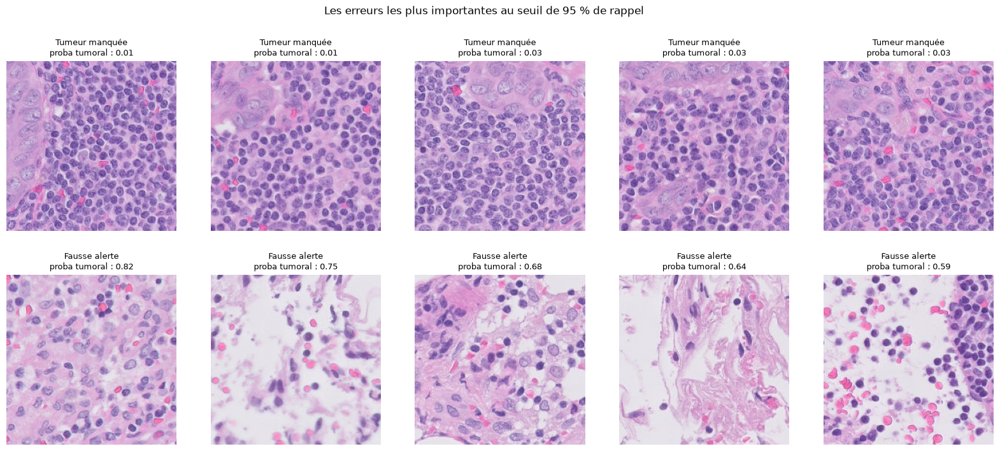

In [61]:
# On regarde les erreurs du modèle (au seuil de 95 % de rappel)

# La vraie réponse en 0/1
predictions["vrai"] = (predictions["etiquette"] == "tumoral").astype(int)
# La réponse du modèle en 0/1
predictions["predit"] = (predictions["proba_tumoral"] >= seuil_rappel_95).astype(int)

# Tumeurs manquées : vraies tumorales, prédites saines. On trie pour avoir les plus ratées en premier (proba la plus faible)
tumeurs_manquees = predictions[(predictions["vrai"] == 1) & (predictions["predit"] == 0)].sort_values("proba_tumoral")
# Fausses alertes : vraies saines, prédites tumorales, les plus sûres en premier
fausses_alertes = predictions[(predictions["vrai"] == 0) & (predictions["predit"] == 1)].sort_values("proba_tumoral", ascending=False)
print("Tumeurs manquées :", len(tumeurs_manquees), "- Fausses alertes :", len(fausses_alertes))

# Grille 2 × 5 : en haut les 5 tumeurs les plus manquées, en bas les 5 fausses alertes les plus nettes
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for i, (nom, erreurs) in enumerate([("Tumeur manquée", tumeurs_manquees), ("Fausse alerte", fausses_alertes)]):
    for j in range(5):
        axes[i, j].axis("off")
        # S'il y a au moins j+1 erreurs, on affiche la j-ième
        if j < len(erreurs):
            p = erreurs.iloc[j]
            axes[i, j].imshow(Image.open(os.path.join(DOSSIER_PATCHS, p["fichier"])))
            axes[i, j].set_title(f"{nom}\nproba tumoral : {p['proba_tumoral']:.2f}", fontsize=9)
plt.suptitle("Les erreurs les plus importantes au seuil de 95 % de rappel")
plt.show()

On observe que les tumeurs manquées semblent concerner des patchs avec plus de tissu sain que tumoral.

Pour les fausses alertes, on observe :
- Des patchs avec des globules rouge (en rose plus vif)
- Des patchs avec des zones assez désorganisées : on n'a pas que des lymphocytes bien organisés

In [62]:
# On regarde la position et la part de tumeur des 10 tumeurs les plus manquées

display(tumeurs_manquees[["lame", "x", "y", "pct_tumeur", "pct_tumeur_centre", "proba_tumoral"]].head(10))

,lame,x,y,pct_tumeur,pct_tumeur_centre,proba_tumoral
53,patient_092_node_1,133504,75264,0.2496,0.1535,0.010612
351,patient_092_node_1,131712,77056,0.1752,0.1169,0.014849
382,patient_092_node_1,126784,77504,0.3199,0.1995,0.026636
26,patient_092_node_1,129024,78400,0.2990,0.0529,0.028055
20,patient_092_node_1,129472,77952,0.5828,0.5430,0.028464
21,patient_092_node_1,129920,77952,0.3013,0.2098,0.033482
323,patient_092_node_1,132160,76608,0.8386,1.0000,0.038982
25,patient_092_node_1,132608,76608,0.3423,0.3561,0.046078
397,patient_092_node_1,125440,76160,0.3925,0.2838,0.090778
370,patient_092_node_1,132608,76160,0.5879,0.6020,0.093138


Les patchs avec tumeurs manquées sont des patchs avec relativement "peu" de celulles tumorales en tous cas pas la majorité de la surface du patch, sauf dans un cas.

Il y a souvent moins de tumeur au centre donc à priori ce sont plutôt des tumeurs sur les bords des patchs.

Pour les patchs 177 et 110, les résultats sont étonnants car la probabilité est faible et le pourcentage de surface avec celulles tumorales élevé. Peut-être aussi de l'imprécision dans les annotations et masques ? Cf ci-dessous pour la lame patient_092_node_1.

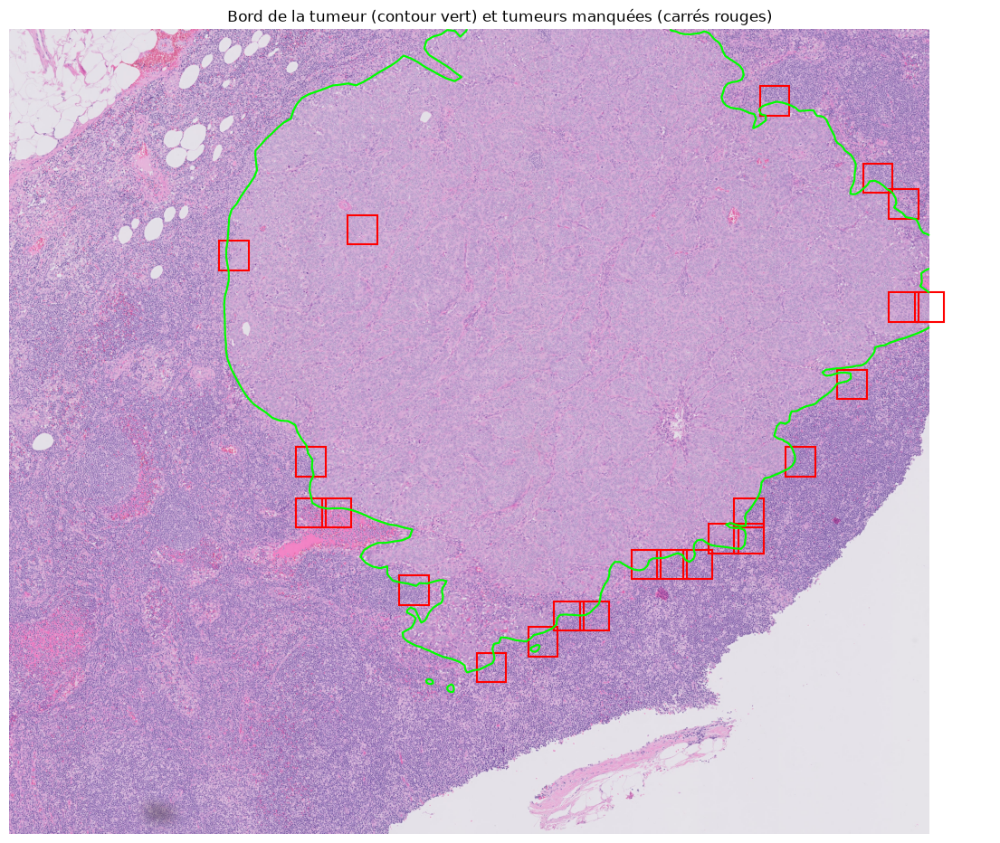

In [63]:
# On regarde où sont les tumeurs manquées sur la lame avec le contour officiel de la tumeur

lame_092 = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, "patient_092_node_1.tif"))
masque_092 = openslide.OpenSlide(os.path.join(DOSSIER_MASQUES, "patient_092_node_1_mask.tif"))

# Coin en haut à gauche de la zone à afficher (les tumeurs manquées sont entre x = 123 000 et 133 000 et y = 71 000 et 80 000)
x0, y0 = 120000, 68000
# Largeur et hauteur de la zone au niveau 0, pour couvrir cette zone
largeur, hauteur = 16000, 14000
# Niveau de lecture
niveau = 2
# De combien le niveau 2 est réduit (4)
facteur = int(lame_092.level_downsamples[niveau])
# La taille de la zone en pixels du niveau 2 (read_region veut la taille dans le niveau lu)
taille = (largeur // facteur, hauteur // facteur)

# La zone de la lame (blanc à la place du transparent) et la même zone du masque (canal 0)
zone_lame = lire_rgb(lame_092, (x0, y0), niveau, taille)
zone_masque = np.array(masque_092.read_region((x0, y0), niveau, taille))[:, :, 0]

fig, ax = plt.subplots(figsize=(14, 12))
ax.imshow(zone_lame)
# contour trace la frontière entre False et True de zone_masque == 2 (le bord de la tumeur), en vert
ax.contour(zone_masque == 2, levels=[0.5], colors="lime", linewidths=1.5)
# Pour chaque tumeur manquée, un carré rouge : position relative à x0, y0, divisée par 4 (repère du niveau 2),
# côté = 512 px au niveau 0 (un patch) / 4
for _, p in tumeurs_manquees.iterrows():
    ax.add_patch(Rectangle(((p["x"] - x0) / facteur, (p["y"] - y0) / facteur), 512 / facteur, 512 / facteur,
                           fill=False, edgecolor="red", linewidth=1.5))
ax.set_title("Bord de la tumeur (contour vert) et tumeurs manquées (carrés rouges)")
ax.axis("off")
plt.show()

### 5.2. Etape 2 - Du patch à la lame

#### 5.2.1. Prédictions pour chaque patch de la lame de validation

On travaille sur la lame de validation, que le modèle n'a pas vu lors de son entrainement.

Il nous faut récupérer la classe prédite pour TOUS les patchs de cette lames. On ne va donc pas enregistrer tous les fichiers ici mais on fera une lecture à la volée : on lira le patch directement dans le fichier TIFF et on n'enregistrera que les prédictions dans un CSV.

On choisit un pas de 112 px ici (alors que 224 px pour l'entrainement du modèle) : 
- Cela nous permettra une meilleure précision sur la taille des zones tumorales : 
    - Avec un pas de 224 px, une case fait 112 µm. Une lésion de 150 µm et une de 210 µm peuvent toutes les deux occuper deux cases alors que l’une est une ITC et l’autre une micro-métastase.
    - Avec un pas de 112 px, une case fait 56 µm donc on mesure plus finement.
- Cela nous permettra aussi de bien identifier une lésion coupée entre plusieurs patchs :
    - Sans chevauchement, une petite lésion peut tomber au coin de plusieurs patchs et elle n’est alors au centre d’aucun. Le modèle risque de la manquer car il a appris à juger le centre du patch (car on a choisi d'étiqueter les patchs en "tumoral" si pixel tumoral dans le centre du patch).
    - Avec un pas de 112 px = la taille de la zone centrale, les zones centrales se touchent et couvrent toute la lame. Chaque endroit du tissu est donc forcément au centre d’un patch.

In [64]:
# On fait les réglages de l'analyse d'une lame entière et on recharge le classifieur

# Pas de 112 px pour analyser une lame entière : les zones centrales (112 px) se touchent et couvrent toute la lame
PAS_LAME_ENTIERE = 112
# On travaille sur la lame de validation que le modèle n'a pas apprise
NOM_LAME = "patient_092_node_1"
# Le dossier où ranger les résultats des lames entières
DOSSIER_LAMES_ENTIERES = os.path.join(DOSSIER_RESULTATS, "lames_entieres")
os.makedirs(DOSSIER_LAMES_ENTIERES, exist_ok=True)

# On recharge le classifieur depuis le fichier, comme on le ferait sur une nouvelle lame
classifieur = joblib.load(os.path.join(DOSSIER_RESULTATS, "classifieur.joblib"))

In [65]:
# Ce que fait la cellule : une fonction qui liste toutes les positions de patchs d'une lame entière
# (comme lister_patchs, mais sans masque, avec les bords, et seulement les patchs avec assez de tissu)

def lister_patchs_lame_entiere(lame, pas=PAS_LAME_ENTIERE):
    # Même détection du tissu qu'à l'entraînement
    tissu = masque_tissu(lame)
    # Facteurs de réduction des niveaux 1 et 5 par rapport au niveau 0
    facteur_patch = int(lame.level_downsamples[NIVEAU_PATCH])
    facteur_tissu = int(lame.level_downsamples[NIVEAU_TISSU])
    # Le côté du patch et le pas en pixels du niveau 0 (448 et 224)
    taille_0 = TAILLE_PATCH * facteur_patch
    pas_0 = pas * facteur_patch
    # Les dimensions de la lame au niveau 0
    largeur_0, hauteur_0 = lame.dimensions

    # Positions de la grille en listes pour pouvoir y ajouter une position
    positions_x = list(range(0, largeur_0 - taille_0 + 1, pas_0))
    positions_y = list(range(0, hauteur_0 - taille_0 + 1, pas_0))
    # + une dernière position collée au bord droit si la grille ne tombe pas pile dessus ([-1] = le dernier élément)
    if positions_x[-1] != largeur_0 - taille_0:
        positions_x.append(largeur_0 - taille_0)
    # Idem pour le bord bas
    if positions_y[-1] != hauteur_0 - taille_0:
        positions_y.append(hauteur_0 - taille_0)

    # Liste qui contiendra une ligne par patch gardé
    patchs = []
    for y in positions_y:
        for x in positions_x:
            # Le carré du patch dans le masque de tissu (positions divisées par 32)
            zone_tissu = tissu[y // facteur_tissu:(y + taille_0) // facteur_tissu,
                               x // facteur_tissu:(x + taille_0) // facteur_tissu]
            # La part de tissu
            pct_tissu = zone_tissu.mean()
            # Même règle des 25 % qu'à l'entraînement : on ne garde que les patchs utilisables
            if pct_tissu >= SEUIL_TISSU:
                patchs.append({"x": x, "y": y, "pct_tissu": round(pct_tissu, 3)})
    return pd.DataFrame(patchs)

# On ouvre la lame une seule fois (le Dataset en aura aussi besoin)
lame = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, NOM_LAME + ".tif"))
# On liste ses patchs
patchs_lame = lister_patchs_lame_entiere(lame)
print(len(patchs_lame), "patchs de tissu à prédire")

58441 patchs de tissu à prédire


On a redéfini ici une fonction car on change quelques petites choses :
- On ajoute si besoin une dernière position collée au bord droit et au bord bas de la lame (pour qu'aucune bande de tissu ne soit oubliée)
- On ne lit plus le masque officiel : c'est le modèle qui donnera la réponse
- On ne garde directement que les patchs avec au moins 25 % de tissu (même règle qu'à l'entraînement). Il n'y a plus de patchs "écartés car ambigus" car l'ambiguïté se repère avec le masque qu'on n'utilise plus
- La fonction reçoit la lame déjà ouverte (et plus son nom) car on l'ouvre maintenant une seule fois en dehors car le Dataset en a aussi besoin pour lire les patchs directement dans la lame

In [ ]:
# On crée un nouveau Dataset qui lit chaque patch directement dans le TIFF de la lame et le chargeur qui va avec

class PatchsLameDataset(Dataset):
    def __init__(self, lame, tableau, transformation):
        # La lame déjà ouverte avec OpenSlide
        self.lame = lame
        # Le tableau des positions, renuméroté de 0 à n-1
        self.tableau = tableau.reset_index(drop=True)
        self.transformation = transformation

    # Combien de patchs ?
    def __len__(self):
        return len(self.tableau)

    # Comment obtenir le patch numéro i ?
    def __getitem__(self, i):
        # La ligne numéro i
        ligne = self.tableau.iloc[i]
        # La position du patch au niveau 0 (OpenSlide veut des entiers Python)
        position = (int(ligne["x"]), int(ligne["y"]))
        # On lit le patch dans la lame, au niveau 1, 224 × 224, avec du blanc à la place du transparent
        image = lire_rgb(self.lame, position, NIVEAU_PATCH, (TAILLE_PATCH, TAILLE_PATCH))
        # Pas d'étiquette (on ne connaît pas la réponse) : on renvoie le numéro du patch à la place
        return self.transformation(image), i

# Le Dataset de la lame 092 et son chargeur (shuffle=False indispensable pour garder l'ordre du tableau)
jeu_lame = PatchsLameDataset(lame, patchs_lame, preparation)
chargeur_lame = DataLoader(jeu_lame, batch_size=64, shuffle=False, num_workers=0)

In [ ]:
# On prédit tous les patchs de la lame entière et on enregistre les probabilités

debut = time.time()
# Les 512 caractéristiques de chaque patch et les numéros des patchs dans l'ordre où ils sont sortis
X_lame, numeros = extraire_caracteristiques(chargeur_lame)
print(f"Caractéristiques : {X_lame.shape}, en {(time.time() - debut) / 60:.1f} min")

# On vérifie que l'ordre est conservé (numéros 0, 1, 2, ...) : sinon assert arrête le notebook avec une erreur
assert (numeros == np.arange(len(patchs_lame))).all()

# La probabilité tumorale de chaque patch est ajoutée au tableau
patchs_lame["proba_tumoral"] = classifieur.predict_proba(X_lame)[:, 1]
# On enregistre le tableau (position, % de tissu, probabilité) qui sert pour la carte de chaleur
patchs_lame.to_csv(os.path.join(DOSSIER_LAMES_ENTIERES, NOM_LAME + "_predictions.csv"), index=False)

# Résumé des probabilités et nombre de patchs au-dessus de 0,5
print(patchs_lame["proba_tumoral"].describe())
print("Patchs avec proba >= 0.5 :", (patchs_lame["proba_tumoral"] >= 0.5).sum())

Caractéristiques : (58441, 512), en 8.3 min
count    58441.000000
mean         0.077617
std          0.134302
min          0.000029
25%          0.008320
50%          0.024160
75%          0.073414
max          0.941576
Name: proba_tumoral, dtype: float64
Patchs avec proba >= 0.5 : 1817


#### 5.2.2. Carte de chaleur

On a maintenant pour chaque patch sa probabilité tumorale. Chaque patch représente un petit carré sur la lame et nous allons maintenant les rassembler dans une carte de chaleur :
- On rassemble les données qu'on a sur les patchs sous la forme d'un tableau 2D où chaque case correspond à un patch
- Les cases sans tissu restent vides
- Pour les cases avec tissu, on met dans la case la probabilité tumorale du patch et la couleur sera ajoutée à l'affichage (rouge quand probabilité élevée, orange quand moyenne, etc)
- Une case = un pixel sur la carte de chaleur (avec sa couleur en fonction de la probabilité)
- Comme on a choisi un pas de 112 px pour des patchs de 224 px, les patchs se chevauchent : chaque carré de 112 px de la lame est couvert par jusqu'à 4 patchs. Chaque pixel de la carte ne peut donc représenter que 112 × 112 px de la lame et on le posera sur la zone centrale du patch car c'est elle que le modèle a appris à juger. D'où le décalage de 56 px quand on superposera la carte à la lame.

In [ ]:
# On range les probabilités dans un tableau 2D (la carte de chaleur)

# Facteur de réduction du niveau 1
facteur_patch = int(lame.level_downsamples[NIVEAU_PATCH])
# 224 : taille d'une case en pixels du niveau 0 (le pas de 112 px au niveau 1)
pas_0 = PAS_LAME_ENTIERE * facteur_patch

# Numéro de colonne et de ligne de chaque patch = position / pas.
# np.ceil arrondit au-dessus (pour les patchs du bord, dont la position n'est pas un multiple du pas)
# .astype(int) en fait des entiers et .to_numpy() des tableaux NumPy simples
colonnes = np.ceil(patchs_lame["x"] / pas_0).astype(int).to_numpy()
lignes = np.ceil(patchs_lame["y"] / pas_0).astype(int).to_numpy()

# Une carte vide de la bonne taille (+1 car les numéros commencent à 0) remplie de NaN (= pas de tissu)
carte = np.full((lignes.max() + 1, colonnes.max() + 1), np.nan)
# On écrit chaque probabilité dans sa case. NumPy associe les trois listes position par position
carte[lignes, colonnes] = patchs_lame["proba_tumoral"].to_numpy()

print("Taille de la carte :", carte.shape, "(lignes, colonnes)")
# ~np.isnan(carte) = True pour les cases remplies - count_nonzero les compte. On doit retrouver le nombre de patchs
print("Cases remplies :", np.count_nonzero(~np.isnan(carte)), "sur", len(patchs_lame), "patchs")

# On enregistre la carte pour pouvoir la recharger sans recalcul
np.save(os.path.join(DOSSIER_LAMES_ENTIERES, NOM_LAME + "_carte.npy"), carte)

Taille de la carte : (401, 806) (lignes, colonnes)
Cases remplies : 58441 sur 58441 patchs


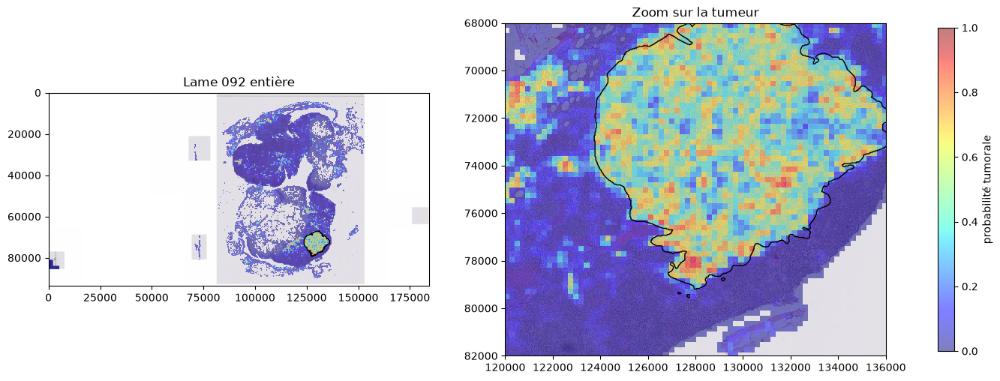

In [ ]:
# On superpose la carte de chaleur à la lame, avec le contour officiel de la tumeur

# On affiche la lame au niveau 5 (réduit 32 fois)
NIVEAU_VUE = 5
facteur_vue = int(lame.level_downsamples[NIVEAU_VUE])
largeur_0, hauteur_0 = lame.dimensions

# La lame au niveau 5 (fond blanc)
vue_lame = lire_rgb(lame, (0, 0), NIVEAU_VUE, lame.level_dimensions[NIVEAU_VUE])

# Le masque officiel au niveau 5 pour tracer le contour de la tumeur (pour vérification seulement)
masque = openslide.OpenSlide(os.path.join(DOSSIER_MASQUES, NOM_LAME + "_mask.tif"))
tumeur_vue = np.array(masque.read_region((0, 0), NIVEAU_VUE, masque.level_dimensions[NIVEAU_VUE]))[:, :, 0] == 2 # On regarde si le canal 0 (avec 0, 1, 2) = 2 donc tumeur
# Le centre de chaque pixel du masque en pixels du niveau 0 (+0,5 = le milieu du pixel) pour l'aligner avec le reste
xs = (np.arange(tumeur_vue.shape[1]) + 0.5) * facteur_vue
ys = (np.arange(tumeur_vue.shape[0]) + 0.5) * facteur_vue

# Où commence la carte : décalée de 56 px au niveau 1 (112 au niveau 0), pour que chaque case tombe sur la zone centrale de son patch
decalage_0 = (TAILLE_PATCH - TAILLE_CENTRE) // 2 * facteur_patch
# La zone occupée par la carte en pixels du niveau 0 : (gauche, droite, bas, haut)
etendue_carte = (decalage_0, decalage_0 + carte.shape[1] * pas_0,
                 decalage_0 + carte.shape[0] * pas_0, decalage_0)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
# On dessine la même chose sur les deux graphiques
for ax in axes:
    # La lame, placée de 0 à largeur_0 et de 0 à hauteur_0 (le bas avant le haut car y augmente vers le bas)
    ax.imshow(vue_lame, extent=(0, largeur_0, hauteur_0, 0))
    # La carte par-dessus : palette jet (bleu = 0, rouge = 1), à moitié transparente, cases nettes
    image_carte = ax.imshow(carte, extent=etendue_carte, cmap="jet", vmin=0, vmax=1,
                            alpha=0.5, interpolation="nearest")
    # Le contour officiel de la tumeur en noir
    ax.contour(xs, ys, tumeur_vue, levels=[0.5], colors="black", linewidths=1)
axes[0].set_title("Lame 092 entière")

# Zoom sur la tumeur (même zone que pour les erreurs) : on limite les axes à cette zone
x0, y0 = 120000, 68000
axes[1].set_xlim(x0, x0 + 16000)
# y à l'envers : le haut de l'image est en haut
axes[1].set_ylim(y0 + 14000, y0)
axes[1].set_title("Zoom sur la tumeur")

# La barre de couleur (probabilité)
fig.colorbar(image_carte, ax=axes, shrink=0.7, label="probabilité tumorale")
plt.show()

On a cherché à dessiner une seule figure où l’on superpose trois couches pour vérifier si les zones que le modèle trouve tumorales tombent bien dans la vraie tumeur :
- Couche 1 = la lame (en fond) lue au niveau 5
- couche 2 = carte de chaleur semi-transparente
- Le contour noir de la vraie tumeur à partir du masque niveau 5

Le problème est que les trois couches n’ont pas la même taille :
- La lame est au niveau 5 avec 1 pixel niveau 5 = 32 pixels niveau 0
- La carte de chaleur a 1 case = 224 pixels du niveau 0 avec un décalage de 112.
- Le masque au niveau 5 avec 1 pixel niveau 5 = 32 pixels du niveau 0

Pour les superposer il faut bien les placer tous au bon endroit sur une échelle commune = les pixels du niveau 0.

#### 5.2.3. De la carte de chaleur à la classe de la lame

Le principe :
- Chaque case devient tumorale si sa probabilité dépasse un seuil (on peut commencer avec celui optimisé sur le rappel mais à voir)
- On regroupe les cases voisines en lésions
- On nettoie c'est à dire qu'on comble les trous à l'intérieur d'une lésion (si on a raté des patchs tumoraux à lintérieur de la lésion donc complètement entourés de patchs tumoraux)
- On mesure chaque lésion
- On classe la lame d'après la plus grande lésion :
    - Pas de lésion : négative
    - Lésion de 0,2 mm au plus : ITC
    - Plus de 0,2 mm et jusqu’à 2 mm : micro-métastase
    - Plus de 2 mm : macro-métastase

On commence par choisir le seuil et on compare pour cela nos résultats avec plusieurs seuils comparés aux masques.

In [71]:
# On fabrique le corrigé de chaque case à partir du masque officiel
# (une case est vraiment tumorale si sa zone centrale contient de la tumeur)

# Une case = 224 px au niveau 0 = 224 / 32 = 7 pixels au niveau 5
cote = pas_0 // facteur_vue
# La zone centrale commence 112 px plus loin au niveau 0 = 3,5 pixels au niveau 5, arrondi à 3 par //
# (décalage d'un demi-pixel du niveau 5, soit 4 µm : négligeable devant une case de 56 µm)
decal = decalage_0 // facteur_vue
# Le nombre de lignes et de colonnes de la carte
nb_lignes, nb_colonnes = carte.shape

# On recopie le masque tumoral dans un tableau assez grand pour contenir toutes les cases
# (les cases du bord peuvent dépasser un peu le masque : ce qui dépasse reste à False)
grand = np.zeros((decal + nb_lignes * cote, decal + nb_colonnes * cote), dtype=bool)
# La partie commune aux deux tableaux (la plus petite des deux hauteurs et des deux largeurs)
h = min(grand.shape[0], tumeur_vue.shape[0])
w = min(grand.shape[1], tumeur_vue.shape[1])
grand[:h, :w] = tumeur_vue[:h, :w]

# On enlève le décalage pour que chaque bloc de 7 × 7 tombe sur la zone centrale d'une case
zone = grand[decal:decal + nb_lignes * cote, decal:decal + nb_colonnes * cote]
# reshape range les pixels par case (ligne de case, ligne dans la case, colonne de case, colonne dans la case),
# puis any(axis=(1, 3)) répond True si au moins un des 49 pixels de la case est tumoral
verite = zone.reshape(nb_lignes, cote, nb_colonnes, cote).any(axis=(1, 3))

# True pour les cases avec tissu (celles qu'on a prédites)
tissu_carte = ~np.isnan(carte)
# On ne juge que les cases de tissu
verite = verite & tissu_carte
print("Cases vraiment tumorales :", verite.sum(), "sur", tissu_carte.sum(), "cases de tissu")

Cases vraiment tumorales : 1980 sur 58441 cases de tissu


,seuil,cases prédites tumorales,VP (dans la tumeur),FP (fausses alertes),FN (tumeur manquée),rappel,précision
0,0.181,7169,1895,5274,85,0.957,0.264
1,0.500,1817,945,872,1035,0.477,0.520
2,0.700,329,161,168,1819,0.081,0.489
3,0.800,87,38,49,1942,0.019,0.437
4,0.900,10,4,6,1976,0.002,0.400


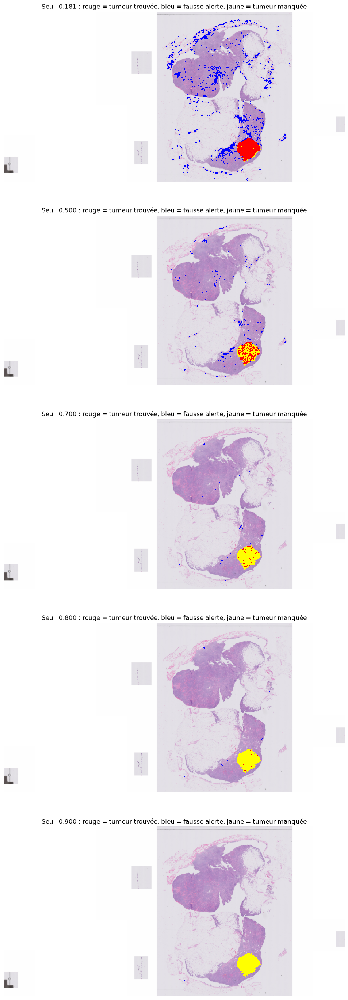

In [ ]:
# On compare plusieurs seuils, case par case, avec le masque

# Les seuils à tester
seuils_a_tester = [seuil_rappel_95, 0.5, 0.7, 0.8, 0.9]
# NaN remplacés par 0 pour pouvoir comparer au seuil (les cases sans tissu ne passent jamais le seuil)
probas = np.where(tissu_carte, carte, 0)

resultats_seuils = []
cartes_erreurs = []
for seuil in seuils_a_tester:
    # Cases prédites tumorales
    predit = tissu_carte & (probas >= seuil)
    # Tumorales trouvées : prédites tumorales ET vraiment tumorales
    vp = (predit & verite).sum()
    # Fausses alertes : prédites tumorales MAIS saines
    fp = (predit & ~verite).sum()
    # Tumeur manquée : prédites saines MAIS tumorales
    fn = (~predit & verite).sum()
    # Une ligne de tableau pour ce seuil, avec le rappel et la précision
    resultats_seuils.append({"seuil": round(float(seuil), 3),
                             "cases prédites tumorales": predit.sum(),
                             "VP (dans la tumeur)": vp, "FP (fausses alertes)": fp, "FN (tumeur manquée)": fn,
                             "rappel": round(vp / (vp + fn), 3), "précision": round(vp / (vp + fp), 3)})
    # Carte des erreurs : 1 = VP, 2 = FP, 3 = FN, NaN = rien à afficher
    erreurs = np.full(carte.shape, np.nan)
    erreurs[predit & verite] = 1
    erreurs[predit & ~verite] = 2
    erreurs[~predit & verite] = 3
    cartes_erreurs.append(erreurs)

tableau_seuils = pd.DataFrame(resultats_seuils)
display(tableau_seuils)

# VP rouge, FP bleu, FN jaune
couleurs = ListedColormap(["red", "blue", "yellow"])
# Un graphique par seuil, les uns sous les autres
fig, axes = plt.subplots(len(seuils_a_tester), 1, figsize=(14, 7 * len(seuils_a_tester)))
# zip avance dans les trois listes en même temps
for ax, seuil, erreurs in zip(axes, seuils_a_tester, cartes_erreurs):
    ax.imshow(vue_lame, extent=(0, largeur_0, hauteur_0, 0))
    ax.imshow(erreurs, extent=etendue_carte, cmap=couleurs, vmin=1, vmax=3, interpolation="nearest")
    ax.set_title(f"Seuil {seuil:.3f} : rouge = tumeur trouvée, bleu = fausse alerte, jaune = tumeur manquée")
    ax.axis("off")
plt.show()

On choisit le seuil de 0,5 vu les résultats (mais pas parfait).

In [73]:
# On crée les fonctions pour passer de la carte aux lésions, mesurer les lésions et classer la lame

# Un carré 3 × 3 de 1 : les 8 voisins (diagonales comprises) comptent comme voisins
VOISINS_8 = np.ones((3, 3), dtype=int)
# Taille d'une case en µm : 224 px du niveau 0 × taille d'un pixel (0,25 µm) = 56 µm
taille_case_um = pas_0 * float(lame.properties["openslide.mpp-x"])
print(f"Une case = {taille_case_um:.1f} µm")

def trouver_lesions(carte, seuil):
    """Seuil unique + comblement des trous. Renvoie la carte des lésions numérotées et leur nombre."""
    # Les NaN (cases sans tissu) deviennent 0 pour pouvoir les comparer au seuil
    probas = np.where(np.isnan(carte), 0, carte)
    # 1) Les cases prédites tumorales (au-dessus du seuil)
    tumoral = probas >= seuil
    # 2) On comble les trous complètement entourés de cases tumorales
    tumoral = ndimage.binary_fill_holes(tumoral)
    # 3) On numérote les groupes de cases tumorales qui se touchent (8 voisins) : chaque groupe est une lésion
    lesions, nb_lesions = ndimage.label(tumoral, structure=VOISINS_8)
    return lesions, nb_lesions

def plus_grande_dimension_um(masque_lesion):
    """Plus grande distance entre deux cases de la lésion en µm."""
    # Le bord = la lésion moins sa version rétrécie d'une case (l'érosion) : la plus grande distance est forcément entre deux cases du bord
    bord = masque_lesion & ~ndimage.binary_erosion(masque_lesion)
    # Les coordonnées (ligne, colonne) des cases du bord
    cases = np.argwhere(bord)
    # Une lésion d'une seule case mesure une case
    if len(cases) == 1:
        return taille_case_um
    # pdist = toutes les distances entre paires de cases (en cases), on prend la plus grande,
    # +1 pour compter les deux demi-cases des extrémités, × la taille d'une case pour avoir des µm
    return (pdist(cases).max() + 1) * taille_case_um

def mesurer_lesions(lesions, verite):
    """Un tableau avec une ligne par lésion : nombre de cases, taille, vraie ou fausse."""
    lignes = []
    # find_objects donne le rectangle qui entoure chaque lésion, enumerate les numérote à partir de 1 (comme les lésions)
    for numero, zone in enumerate(ndimage.find_objects(lesions), start=1):
        # True seulement pour les cases de cette lésion, dans son rectangle
        masque_lesion = lesions[zone] == numero
        lignes.append({"lesion": numero,
                       "nb_cases": int(masque_lesion.sum()),
                       "taille_um": plus_grande_dimension_um(masque_lesion),
                       # vraie si au moins une de ses cases est vraiment tumorale d'après le corrigé
                       "vraie": bool(verite[zone][masque_lesion].any())})
    # columns=... pour avoir les bonnes colonnes même s'il n'y a aucune lésion
    return pd.DataFrame(lignes, columns=["lesion", "nb_cases", "taille_um", "vraie"])

def classer_lame(taille_max_um):
    # Aucune lésion
    if taille_max_um == 0:
        return "négative"
    # Jusqu'à 0,2 mm
    if taille_max_um <= 200:
        return "ITC"
    # Jusqu'à 2 mm
    if taille_max_um <= 2000:
        return "micro"
    # Au-delà de 2 mm
    return "macro"

Une case = 56.0 µm


In [ ]:
# On calcule la classe de la lame 092 avec le seuil retenu (seuil unique de 0,5)

SEUIL_LAME = 0.5
lesions, nb_lesions = trouver_lesions(carte, SEUIL_LAME)
# Le tableau des lésions
tableau_lesions = mesurer_lesions(lesions, verite)
# La plus grande lésion (0 s'il n'y en a aucune)
taille_max = tableau_lesions["taille_um"].max() if nb_lesions > 0 else 0
# En mm (÷ 1 000) avec la classe
print(f"Plus grande lésion : {taille_max / 1000:.2f} mm - Classe : {classer_lame(taille_max)}")

Plus grande lésion : 3.12 mm - classe : macro


La lame est bien classée en macro comme attendu.

### 5.3. Etape 3 - De la lame à la patiente

In [75]:
# Toute la chaîne est rangée dans une fonction (pour l'appliquer à plusieurs lames)
# + fonction qui donne le stade pN à partir des classes des ganglions

SEUIL_LAME = 0.5

def analyser_lame(nom_lame, seuil=SEUIL_LAME):
    """Toute la chaîne pour une lame : patchs → probabilités → carte → lésions → classe."""
    # On ouvre la lame (nom différent de lame pour ne pas écraser la 092)
    lame_a = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, nom_lame + ".tif"))
    # Le fichier où sont (ou seront) enregistrées ses prédictions
    chemin_csv = os.path.join(DOSSIER_LAMES_ENTIERES, nom_lame + "_predictions.csv")

    # 1) Probabilités de tous les patchs (on relit le CSV si la lame a déjà été prédite, pour ne pas tout refaire)
    if os.path.exists(chemin_csv):
        patchs = pd.read_csv(chemin_csv)
    else:
        debut = time.time()
        patchs = lister_patchs_lame_entiere(lame_a)
        chargeur = DataLoader(PatchsLameDataset(lame_a, patchs, preparation),
                              batch_size=64, shuffle=False, num_workers=0)
        X, numeros = extraire_caracteristiques(chargeur)
        assert (numeros == np.arange(len(patchs))).all()
        patchs["proba_tumoral"] = classifieur.predict_proba(X)[:, 1]
        patchs.to_csv(chemin_csv, index=False)
        print(f"{nom_lame} : {len(patchs)} patchs prédits en {(time.time() - debut) / 60:.1f} min")

    # 2) Carte de chaleur (comme pour la 092)
    pas = PAS_LAME_ENTIERE * int(lame_a.level_downsamples[NIVEAU_PATCH])
    colonnes = np.ceil(patchs["x"] / pas).astype(int).to_numpy()
    lignes = np.ceil(patchs["y"] / pas).astype(int).to_numpy()
    carte_a = np.full((lignes.max() + 1, colonnes.max() + 1), np.nan)
    carte_a[lignes, colonnes] = patchs["proba_tumoral"].to_numpy()

    # 3) Lésions (seuil unique) et taille de chacune (liste construite en une ligne)
    lesions_a, nb_lesions_a = trouver_lesions(carte_a, seuil)
    tailles = [plus_grande_dimension_um(lesions_a[zone] == numero)
               for numero, zone in enumerate(ndimage.find_objects(lesions_a), start=1)]
    # La plus grande (default=0 s'il n'y a aucune lésion)
    taille_max = max(tailles, default=0)

    # 4) Classe de la lame, rangée dans un dictionnaire avec les autres infos
    resultat = {"lame": nom_lame, "nb patchs": len(patchs), "nb lésions": nb_lesions_a,
                "plus grande lésion (mm)": round(taille_max / 1000, 2),
                "classe prédite": classer_lame(taille_max)}
    # On renvoie le résultat et la carte (pour l'afficher ensuite)
    return resultat, carte_a

def stade_pN(classes):
    """Règles de CAMELYON17 : du classement des ganglions au stade pN de la patiente."""
    # Nombre de macro-métastases
    nb_macro = classes.count("macro")
    # Ganglions positifs = micro ou macro (les ITC ne comptent pas)
    nb_positifs = nb_macro + classes.count("micro")
    # Aucun positif : pN0, ou pN0(i+) s'il y a des ITC
    if nb_positifs == 0:
        return "pN0(i+)" if "ITC" in classes else "pN0"
    # Seulement des micro-métastases
    if nb_macro == 0:
        return "pN1mi"
    # 1 à 3 ganglions positifs, dont au moins une macro
    if nb_positifs <= 3:
        return "pN1"
    # 4 à 9 ganglions positifs, dont au moins une macro
    return "pN2"

In [76]:
# On analyse les 5 lames de test et on calcule le stade pN de la patiente 99

# On relit la sélection et on garde les lames de test
selection = pd.read_csv("../data/prototype/selection_lames_prototype.csv")
lames_test = selection[selection["set"] == "test"]

# Une ligne de résultat par lame, et un dictionnaire {nom de la lame: carte}
resultats_test = []
cartes_test = {}
for _, ligne in lames_test.iterrows():
    # Toute la chaîne pour cette lame
    resultat, carte_a = analyser_lame(ligne["lame"])
    # On ajoute la vraie classe (de stages.csv) pour comparer
    resultat["vraie classe"] = ligne["classe"]
    resultats_test.append(resultat)
    cartes_test[ligne["lame"]] = carte_a

tableau_test = pd.DataFrame(resultats_test)
display(tableau_test)

# Stade prédit (à partir des classes prédites) et vrai stade (à partir des vraies classes)
stade_predit = stade_pN(list(tableau_test["classe prédite"]))
stade_vrai = stade_pN(list(tableau_test["vraie classe"]))
print(f"Stade pN prédit : {stade_predit}   |   vrai stade : {stade_vrai}")

patient_099_node_0 : 27295 patchs prédits en 3.7 min
patient_099_node_1 : 89055 patchs prédits en 11.3 min
patient_099_node_2 : 64373 patchs prédits en 7.1 min
patient_099_node_3 : 37153 patchs prédits en 3.7 min
patient_099_node_4 : 81068 patchs prédits en 8.5 min


,lame,nb patchs,nb lésions,plus grande lésion (mm),classe prédite,vraie classe
0,patient_099_node_0,27295,327,3.67,macro,negative
1,patient_099_node_1,89055,78,0.51,micro,negative
2,patient_099_node_2,64373,447,4.33,macro,negative
3,patient_099_node_3,37153,253,1.29,micro,negative
4,patient_099_node_4,81068,286,3.13,macro,macro


Stade pN prédit : pN2   |   vrai stade : pN1


Les résultats ne sont pas très bons : 4 lames négatives classées en micro voire macro !

In [78]:
# On enregistre les résultats (classes des lames de test + stade pN)

# Les classes des 5 lames de test
tableau_test.to_csv(os.path.join(DOSSIER_RESULTATS, "resultats_lames_test.csv"), index=False)

# Le stade de la patiente, dans un petit tableau d'une ligne
pd.DataFrame([{"patiente": 99, "stade prédit": stade_predit, "vrai stade": stade_vrai,
               "seuil": SEUIL_LAME}]).to_csv(os.path.join(DOSSIER_RESULTATS, "resultat_patiente_test.csv"), index=False)

print("Enregistré dans", DOSSIER_RESULTATS)

Enregistré dans ../data/prototype/resultats/


### 5.4. Interpréter les résultats obtenus

On veut comprendre pourquoi le modèle prend ses décisions et pouvoir comprendre les erreurs. 
La seule "boîte noire" est au niveau du patch : les niveaux lame et patiente sont des règles écrites par nous. 

On va utiliser Grad-CAM au niveau du patch pour voir où le modèle a vu ce qui l'a fait dire "tumoral" dans un patch qui n'aurait pas dû l'être.

Voici le principe :
- A la sortie du bloc 4 de ResNet18, chaque patch donne 512 cartes de 7 × 7 (une par filtre). Chaque carte dit où son motif est présent dans le patch. Les 512 caractéristiques qu'on utilise sont les moyennes de ces cartes.
- On donne un poids à chaque carte qui représente à quel point son motif fait pencher le modèle vers "tumoral".
- On fait la somme des 512 cartes multipliées par leur poids, case par case, et on ne garde que le positif (ce qui pousse vers "tumoral") puis on agrandit la carte de 7 × 7 à 224 × 224 pour la supperposer au patch.

On l'applique de deux façons :
- Sur la lame de validation 092 on regarde une galerie des fausses alertes (celles où le modèle s'est beaucoup trompé et quelques bonnes prédiction pour voir)
- Sur la patiente de test 99, pour chaque lame mal classée on regarde les patchs les plus "surs" de sa plus grande lésion

On ne le fait que sur quelques patchs.

In [82]:
# On prépare Grad-CAM : ResNet18 sans sa moyenne finale (pour garder les 512 cartes de 7 × 7) et le poids de chaque carte

# Les morceaux de ResNet18 dans l'ordre : conv1, bn1, relu, maxpool, layer1 à layer4, avgpool (la moyenne), fc (Identity chez nous)
# [:-2] = tous sauf les deux derniers : la sortie n'est plus 512 caractéristiques mais 512 cartes de 7 × 7
extracteur = torch.nn.Sequential(*list(modele.children())[:-2]).to(appareil)
# Mode évaluation (BatchNorm avec les moyennes apprises) comme pour l'extraction des caractéristiques
extracteur.eval()

# Les deux étapes du pipeline enregistré : [0] la standardisation, [-1] la régression logistique
standardisation = classifieur[0]
regression = classifieur[-1]
# Le poids de chaque carte = coefficient de sa caractéristique / écart-type de cette caractéristique
# (la régression logistique travaille sur les caractéristiques standardisées : (valeur - moyenne) / écart-type)
poids_cartes = regression.coef_[0] / standardisation.scale_
print("Poids des cartes :", poids_cartes.shape, "- min", round(float(poids_cartes.min()), 3), "- max", round(float(poids_cartes.max()), 3))
print("Cartes qui poussent vers 'tumoral' :", (poids_cartes > 0).sum(), "- vers 'sain' :", (poids_cartes < 0).sum())

Poids des cartes : (512,) - min -0.242 - max 0.224
Cartes qui poussent vers 'tumoral' : 201 - vers 'sain' : 311


In [83]:
# On crée deux fonctions : calculer la carte Grad-CAM de quelques patchs et l'afficher

def calculer_gradcam(lame_os, positions):
    """Pour une lame ouverte et une liste de positions (x, y) au niveau 0, renvoie les patchs (images) et leurs cartes Grad-CAM (224 × 224)."""
    # zip(...) ne se parcourt qu'une fois : on en fait une vraie liste
    positions = list(positions)
    images = []
    tenseurs = []
    for x, y in positions:
        # On lit le patch dans la lame, comme pour la prédiction (niveau 1, 224 × 224, blanc à la place du transparent)
        image = lire_rgb(lame_os, (int(x), int(y)), NIVEAU_PATCH, (TAILLE_PATCH, TAILLE_PATCH))
        images.append(image)
        # Même préparation qu'à l'entraînement (tenseur + standardisation ImageNet)
        tenseurs.append(preparation(image))
    # On empile les tenseurs en un seul lot : (nombre de patchs, 3, 224, 224)
    lot = torch.stack(tenseurs).to(appareil)
    with torch.no_grad():
        # Les 512 cartes de 7 × 7 de chaque patch : (nombre de patchs, 512, 7, 7), ramenées en NumPy
        cartes_bloc4 = extracteur(lot).cpu().numpy()
    # Chaque carte multipliée par son poids : poids_cartes[None, :, None, None] a la forme (1, 512, 1, 1),
    # NumPy le "répète" sur les patchs et sur les 7 × 7 cases. Puis .sum(axis=1) additionne les 512 cartes, case par case
    cams = (poids_cartes[None, :, None, None] * cartes_bloc4).sum(axis=1)
    # On ne garde que ce qui pousse vers "tumoral" (les valeurs négatives deviennent 0)
    cams = np.maximum(cams, 0)
    # On agrandit chaque carte de 7 × 7 à 224 × 224 (× 32), avec un lissage entre cases voisines (order=1)
    cams = np.stack([ndimage.zoom(c, TAILLE_PATCH / c.shape[0], order=1) for c in cams])
    return images, cams

def afficher_gradcam(images, cams, titres, titre_figure, vmax=None):
    """Affiche chaque patch (ligne du haut) et sa carte Grad-CAM superposée (ligne du bas)."""
    n = len(images)
    # Rien à afficher
    if n == 0:
        print("Aucun patch à afficher :", titre_figure)
        return
    # Échelle de couleurs : la même pour toutes les images si on la donne, sinon le maximum de cette figure
    if vmax is None:
        vmax = cams.max()
    # squeeze=False : axes reste un tableau 2D même avec une seule colonne
    fig, axes = plt.subplots(2, n, figsize=(4 * n, 8.5), squeeze=False)
    # Où commence la zone centrale (56 px)
    debut_centre = (TAILLE_PATCH - TAILLE_CENTRE) // 2
    for j in range(n):
        # En haut : le patch seul
        axes[0, j].imshow(images[j])
        axes[0, j].set_title(titres[j], fontsize=9)
        # En bas : le patch + la carte Grad-CAM (cases à 0 transparentes grâce à np.ma, rouge = pousse fort vers "tumoral")
        axes[1, j].imshow(images[j])
        axes[1, j].imshow(np.ma.masked_where(cams[j] <= 0, cams[j]), cmap="jet", vmin=0, vmax=vmax, alpha=0.45)
        # La zone centrale en pointillés blancs sur les deux images (c'est elle que le modèle a appris à juger)
        for i in range(2):
            axes[i, j].add_patch(Rectangle((debut_centre, debut_centre), TAILLE_CENTRE, TAILLE_CENTRE,
                                           fill=False, edgecolor="white", linewidth=1, linestyle="--"))
            axes[i, j].axis("off")
    plt.suptitle(titre_figure)
    plt.show()

#### 5.4.1. Quelques fausses alertes sur la lame de validation 092

Sur la lame de validation le masque dit où est la vraie tumeur. On peut donc retrouver les fausses alertes*(patchs prédits tumoraux dont la case n'est pas tumorale) et les vrais positifs et regarder avec Grad-CAM ce que le modèle a vu.

Fausses alertes : 872 - vrais positifs : 945


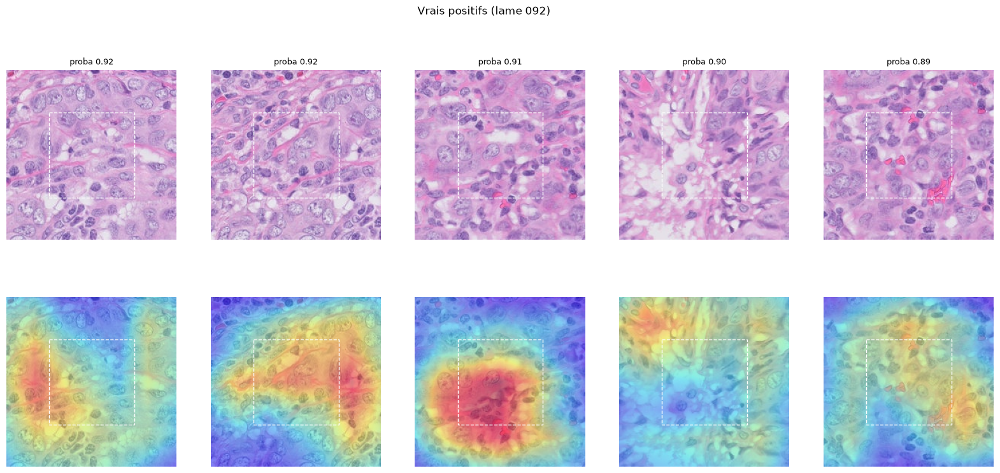

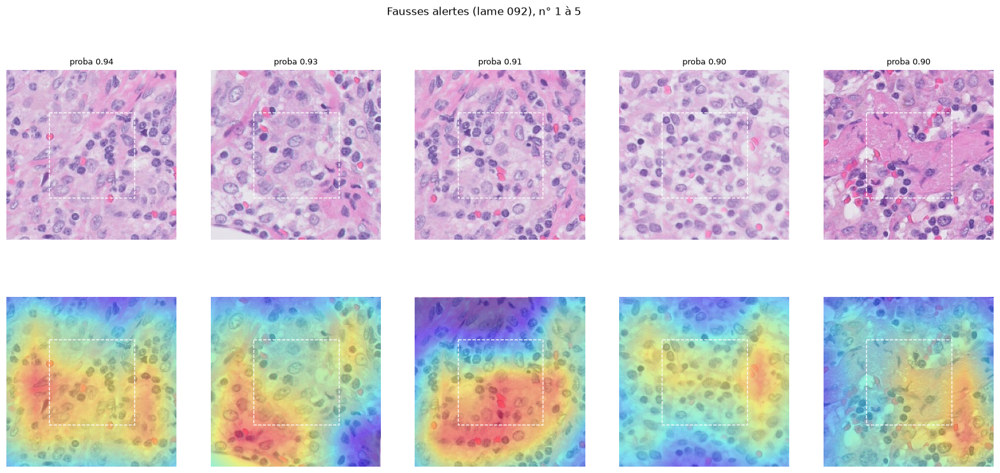

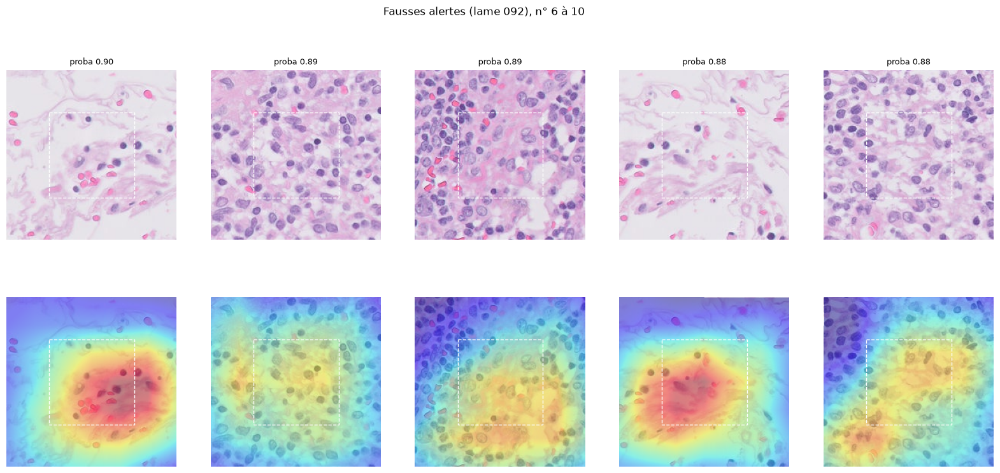

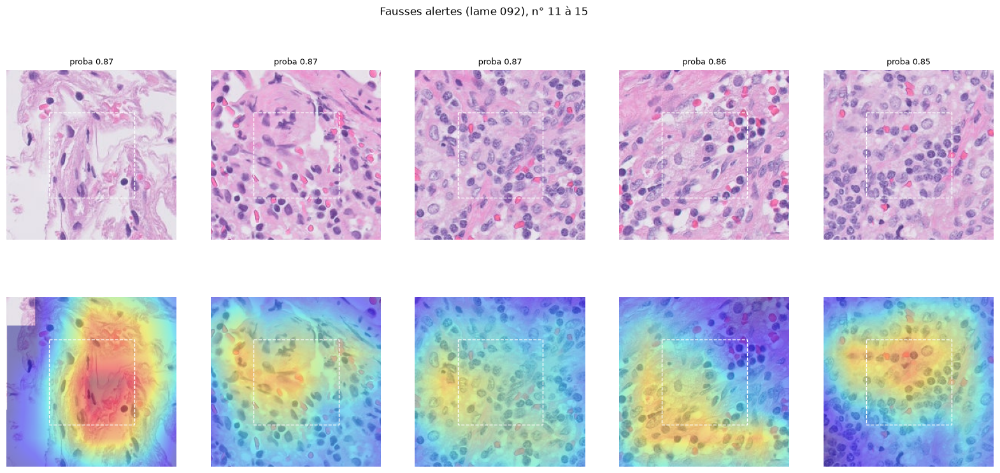

In [87]:
# On retrouve les fausses alertes et les vrais positifs de la 092 et on affiche les plus "sûrs" avec leur Grad-CAM

# La lame de validation (rouverte sous un autre nom pour ne rien écraser)
lame_val = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, NOM_LAME + ".tif"))
# Ses prédictions (positions + probabilités), relues dans le CSV de la 5.2.1
patchs_val = pd.read_csv(os.path.join(DOSSIER_LAMES_ENTIERES, NOM_LAME + "_predictions.csv"))
# Ligne et colonne de chaque patch dans la carte (même calcul que pour construire la carte de chaleur)
patchs_val["ligne"] = np.ceil(patchs_val["y"] / pas_0).astype(int)
patchs_val["colonne"] = np.ceil(patchs_val["x"] / pas_0).astype(int)
# La vérité de sa case d'après le masque (True = vraiment tumorale)
patchs_val["vraie_tumeur"] = verite[patchs_val["ligne"].to_numpy(), patchs_val["colonne"].to_numpy()]
# Prédit tumoral au seuil retenu pour les lames
patchs_val["predit_tumoral"] = patchs_val["proba_tumoral"] >= SEUIL_LAME

# Fausses alertes : prédites tumorales mais saines ; vrais positifs : prédites tumorales et tumorales. Triées de la plus sûre à la moins sûre
fausses_alertes_val = patchs_val[patchs_val["predit_tumoral"] & ~patchs_val["vraie_tumeur"]].sort_values("proba_tumoral", ascending=False)
vrais_positifs_val = patchs_val[patchs_val["predit_tumoral"] & patchs_val["vraie_tumeur"]].sort_values("proba_tumoral", ascending=False)
print("Fausses alertes :", len(fausses_alertes_val), "- vrais positifs :", len(vrais_positifs_val))

# Les 5 vrais positifs et les 15 fausses alertes les plus "sûrs" pour le modèle
choix_vp = vrais_positifs_val.head(5)
choix_fp = fausses_alertes_val.head(15)
images_vp, cams_vp = calculer_gradcam(lame_val, zip(choix_vp["x"], choix_vp["y"]))
images_fp, cams_fp = calculer_gradcam(lame_val, zip(choix_fp["x"], choix_fp["y"]))
# Une même échelle de couleurs pour toutes les images, pour pouvoir les comparer
echelle = max(cams_vp.max(), cams_fp.max())

afficher_gradcam(images_vp, cams_vp, [f"proba {p:.2f}" for p in choix_vp["proba_tumoral"]],
                 "Vrais positifs (lame 092)", echelle)
# Les fausses alertes par groupes de 5 (range(0, 15, 5) = 0, 5, 10)
for debut in range(0, len(images_fp), 5):
    afficher_gradcam(images_fp[debut:debut + 5], cams_fp[debut:debut + 5],
                     [f"proba {p:.2f}" for p in choix_fp["proba_tumoral"].iloc[debut:debut + 5]],
                     f"Fausses alertes (lame 092), n° {debut + 1} à {debut + 5}", echelle)

#### 5.4.2. Chercher à comprendre les erreurs de la patiente de test 99


Pour chaque lame de la patiente 99 dont la classe prédite est fausse, on reprend sa carte de chaleur, on retrouve sa plus grande lésion et on affiche les 5 patchs les plus "sûrs" de cette lésion avec leur Grad-CAM.

,lame,nb lésions,plus grande lésion (mm),classe prédite,vraie classe
0,patient_099_node_0,327,3.67,macro,negative
1,patient_099_node_1,78,0.51,micro,negative
2,patient_099_node_2,447,4.33,macro,negative
3,patient_099_node_3,253,1.29,micro,negative


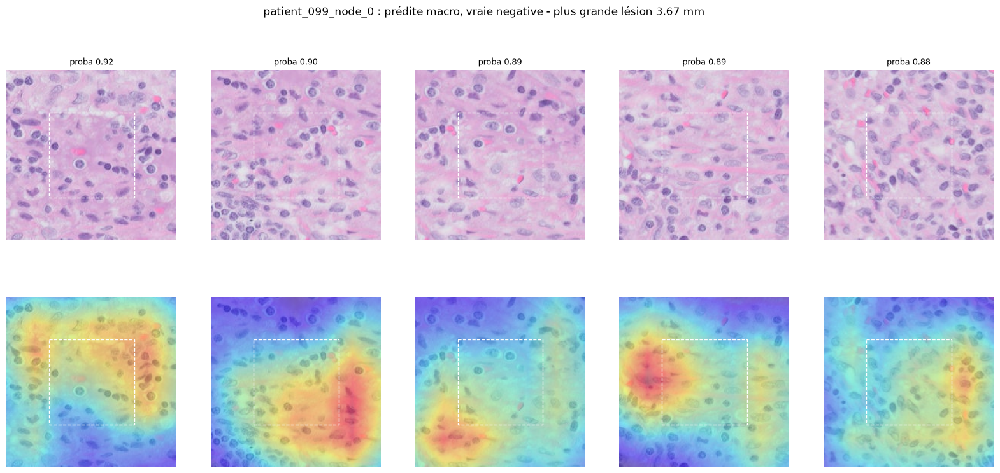

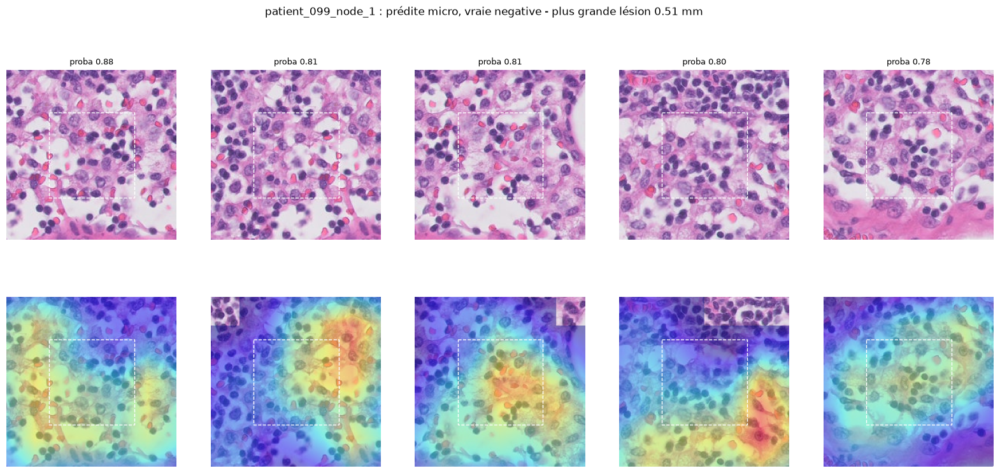

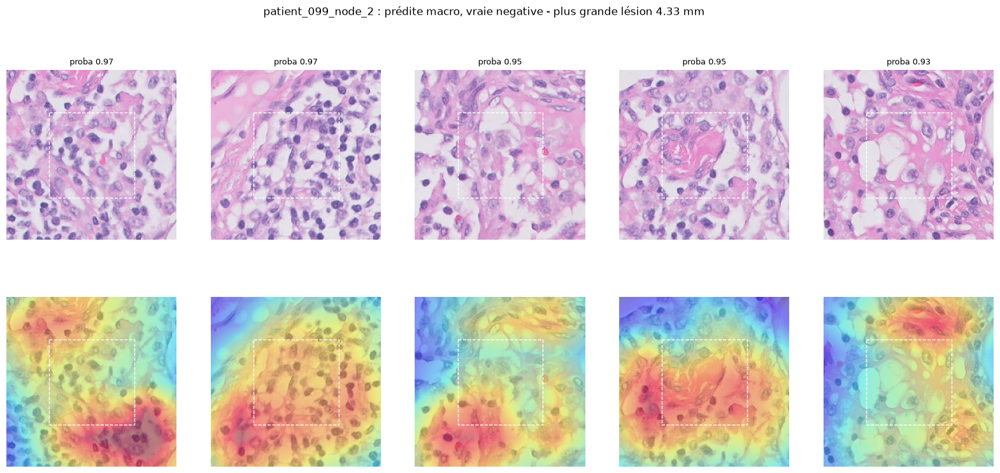

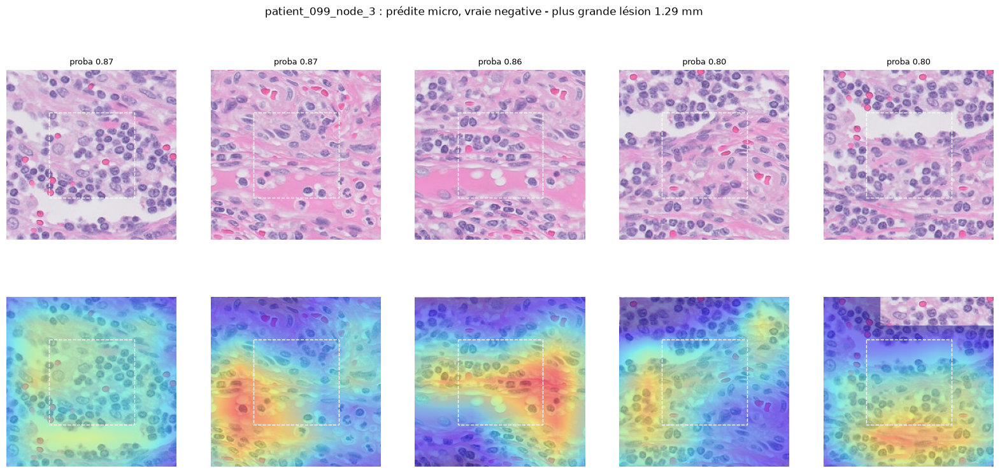

In [85]:
# Pour chaque lame mal classée de la patiente 99 : les patchs les plus "sûrs" de sa plus grande lésion, avec leur Grad-CAM

# Les vraies classes (stages.csv) ne s'écrivent pas comme les nôtres : on les traduit pour pouvoir comparer
correspondance = {"negative": "négative", "itc": "ITC", "micro": "micro", "macro": "macro"}
mal_classees = tableau_test[tableau_test["classe prédite"] != tableau_test["vraie classe"].map(correspondance)]
display(mal_classees[["lame", "nb lésions", "plus grande lésion (mm)", "classe prédite", "vraie classe"]])

for _, ligne in mal_classees.iterrows():
    nom = ligne["lame"]
    # La lame et ses prédictions (CSV enregistré par analyser_lame)
    lame_t = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, nom + ".tif"))
    patchs_t = pd.read_csv(os.path.join(DOSSIER_LAMES_ENTIERES, nom + "_predictions.csv"))
    # Ligne et colonne de chaque patch dans sa carte
    pas_t = PAS_LAME_ENTIERE * int(lame_t.level_downsamples[NIVEAU_PATCH])
    patchs_t["ligne"] = np.ceil(patchs_t["y"] / pas_t).astype(int)
    patchs_t["colonne"] = np.ceil(patchs_t["x"] / pas_t).astype(int)

    # Les lésions de sa carte, avec le même seuil
    lesions_t, nb_lesions_t = trouver_lesions(cartes_test[nom], SEUIL_LAME)
    if nb_lesions_t == 0:
        continue
    # La taille de chaque lésion, puis le numéro de la plus grande (argmax donne sa position dans la liste, +1 car les lésions sont numérotées à partir de 1)
    tailles = [plus_grande_dimension_um(lesions_t[zone] == numero)
               for numero, zone in enumerate(ndimage.find_objects(lesions_t), start=1)]
    numero_max = int(np.argmax(tailles)) + 1

    # True pour les patchs dont la case appartient à cette lésion
    dans_lesion = lesions_t[patchs_t["ligne"].to_numpy(), patchs_t["colonne"].to_numpy()] == numero_max
    # Ses 5 patchs les plus "sûrs"
    choix = patchs_t[dans_lesion].sort_values("proba_tumoral", ascending=False).head(5)
    images_t, cams_t = calculer_gradcam(lame_t, zip(choix["x"], choix["y"]))
    afficher_gradcam(images_t, cams_t, [f"proba {p:.2f}" for p in choix["proba_tumoral"]],
                     f"{nom} : prédite {ligne['classe prédite']}, vraie {ligne['vraie classe']} - plus grande lésion {max(tailles) / 1000:.2f} mm",
                     echelle)

## 6. Notes pour la version finale à partir des résultats observés sur le prototype

### 6.1. Notes sur les modifications de décisions concernant la sélection des lames pour chaque set

1. **Combien de centres ?**
- Prototype : un seul centre pour aller vite.
- Version finale : les 5 centres à l'entraînement, à la validation et au test pour que le modèle apprenne les couleurs et les scanners de chacun + avec le même nombre de lames par centre pour pouvoir regarder les résultats par centre.
- Si le temps le permet : réentraîner la régression logistique sans un centre et l'évaluer sur ce centre (à faire pour chacun des 5 centres).

2. **Combien de lames ?**
- Prototype : 3 lames d'entraînement, 1 lame de validation et 1 patiente de test (avec ses 5 lames).
- Version finale :
    - entraînement : 5 lames annotées + 2 lames négatives pour chacun des centres
    - validation : 1 lame annotée pour chacun des centres
    - test : 1 patiente (5 lames) par centre

3. **Comment choisir les lames annotées ?**
- Prototype : les plus petits fichiers pour gagner du temps et de la place.
- Version finale : il n'y a que 10 lames annotées par centre et on en prendra 5. Il faut prendre des macro et micro. La lame de validation doit contenir assez de tumeur.

4. **Les lames négatives ont-elles besoin d'un masque ?**
- Prototype : on avait pris une lame négative avec un masque.
- Version finale : non pas forcément car une lame négative ne contient pas de tumeur donc tous ses patchs de tissu sont sains et le tissu est repéré par la saturation. Pas besoin du masque.

5. **Comment choisir les patientes de test ?**
- Prototype : la patiente avec au moins une lame annotée dont les fichiers étaient les plus petits.
- Version finale : pas forcément besoin de lames annotées car on compare avec la classe de la lame et le stade pN de la patiente (comme on a "peu" de lames annotées on les garde en tous cas en priorité pour l'entrainement et la validation). Il nous faut par contre des patientes avec des stades différents.

6. **Éviter les fuites de données**
- Prototype et version finale : chaque patiente n'est que dans un seul groupe (entraînement, validation ou test).

### 6.2. Notes sur les modifications de décisions concernant le découpage des patchs

1. **Quelle surface choisir ? À quel niveau découper ? Quelle taille de patch choisir ?**
- Prototype : 224 × 224 pixels (112 µm) soit de même que les 224 pixels des images d'entraînement de ResNet18.
- Version finale : de même ***avec des ajustements*** :
    - Comme la taille des pixels peut varier d'un centre à l'autre (ils n'utilisent pas les mêmes scanners donc n'auront pas la même résolution) on lira une surface fixe de 112 µm qu'on redimensionnera en 224 pixels au lieu de lire à une taille fixe en pixels.
    - On testera plusieurs niveaux pour voir lequel donne les meilleures performances.

2. **Quel pas ?**
- Prototype : 224 px sans chevauchement pour l'entraînement et la validation. Pour l'analyse des lames entières, 112 px avec 50 % de chevauchement.
- Version finale : de même.

3. **Comment repérer le tissu ?**
- Prototype : par les couleurs (plus précisément la saturation) pour toutes les lames.
- Version finale : même logique de base mais avec ***deux ajustements dont un à tester*** :
    - On retire les toutes petites taches détectées comme du tissu qui sont souvent des poussières ou des débris
    - On vérifie que le seuil de 0,04 est adapté à chaque centre avec une lame de chaque centre ou on passe sur un seuil calculé automatiquement pour chaque lame

4. **Uniformiser les couleurs des patchs (différences entre centres)?**
- Prototype : non.
- Version finale : ***à tester***. On peut utiliser une normalisation des colorations sur la base d'une lame de référence donc il faut comparer avec et sans pour voir la différence.

5. **Combien de tissu minimum par patch ?**
- Prototype : au moins 25 %, mesuré sur le patch entier, avec la même règle pour tous les patchs.
- Version finale : ***à tester***. Il paraitrait peut-être plus cohérent de regarder la part dans la zone centrale.

6. **Comment étiqueter un patch ?**
- Prototype : tumoral s'il y a de la tumeur dans la zone centrale, sain s'il n'y a aucune tumeur dans le patch, écarté sinon.
- Version finale : de même.

7. **Quel équilibre entre les classes ?**
- Prototype : équilibre 50/50 par sous-échantillonnage des patchs sains.
- Version finale : **à tester**. La majorité de nos erreurs vient de patchs sains prédits tumoraux donc il semblerait que le modèle doive voir plus de tissu sain varié. On va donc tester de comparer plusieurs équilibres (par exemple 50/50 à 25/75) sur les lames de validation. Si déséquilibre, on compensera avec class_weight="balanced". On gardera un plafond de nombre max de patchs tumoraux par lame pour éviter d'avoir beaucoup de patchs d'une lame macro par exemple. Le plafond est à fixer par tests.

8. **Comment enregistrer les patchs?**
- Prototype : un tableau CSV et des PNG pour l'entraînement et la validation et lecture à la volée pour le test. On enregistre toujours les prédictions.
- Version finale : **modifié**. On lit à la volée pour tous les patchs.

### 6.3. Notes sur les modifications de décisions concernant le modèle de patchs

**Ce qu'on ne modifie pas :**
- preparation
- Le Dataset et le DataLoader (on garde la mêm taille de lot)
- ResNet18
- Extraire les caractéristiques pour chaque patch
- La régression logistique
- L’AUC comme score
- L’analyse des erreurs en images.

**Ce qu'on change :**

- Il faut ajouter des colonnes au tableau des patchs pour avoir l'inormation du centre et de la patiente : patiente pour pouvoir faire une validation croisée et centre pour regarder les résultats par centre.
- L’hyperparameter tuning sera fait par validation croisée regroupée par patiente (et non sur une seule lame de validation). On utilisera GridSearchCV. On peut voir pour limiter le gridsearch à L2 seulement, avec C qui règlera la force.
- Ajouter class_weight="balanced" dans la régression logistique si on ne part pas sur un équilibre 50/50.
- Les lames de validation ne servent plus à optimiser le modèle (ce qu'on faisait dans le prototype) car on utilise une validation croisée sur le set d'entrainement. Par contre, on s'en servira pour vérifier que le modèle retenu marche sur de nouvelles patientes et voir la performance centre par centre + pour choisir le seuil de la lame entière et vérifier les classes (les étapes suivantes).
- On avait choisit le seuil qui permettait d'avoir un rappel de 95% dans le prototype mais on a vu qu'au niveau de la lame les résultats n'étaient pas bon avec ce seuil (car il y a plus de patchs sains sur la lame entière, patchs sur lesquels le modèle se trompait...). On choisira donc le seuil sur la base des performance de la lame entière plutôt.

### 6.4. Notes sur les modifications de décisions concernant les lames entières

**Ce qu'on ne modifie pas :**

- Le pas = à la zone centrale
- La lecture à la volée avec le Dataset qui lit chaque patch dans la lame
- Le CSV des probabilités par lame
- La construction de la carte de chaleur
- La comparaison case par case vs masque pour diagnostic
- Les étapes de comblement des trous, détection des groupes (lésions), calcul de la plus grande dimension

**Ce qu'on change :**

- La lecture à surface fixe en micromètres et non pixels (même sujet que pour le découpage)
- On ajoute l’enregistrement des caractéristiques de chaque lame
- On ajoute l’enregistrement de la carte de chaque lame
- On teste plusieurs seuils et on garde celui qui classe correctement le plus de lames.
- On ajoute un tableau de synthèse des lames de validation : centre, classe vraie, classe prédite, plus grande lésion, plus grande fausse lésion pour voir rapidement les erreurs

### 6.5. Notes sur les modifications de décisions concernant l'étape lame > patiente

1. **Que garde-t-on en mémoire pour ne pas tout recalculer ?**
- Prototype : les probabilités de chaque patch (CSV), relues si elles existent mais le risque est que si on change la régression logistique on relit des probabilités qui ne sont plus bonnes.
- Version finale : les 512 caractéristiques de chaque patch et on recalcule toujours les probabilités avec la régression logistique.

2. **Quel vrai stade ?**
- Prototype : recalculé à partir des vraies classes des lames avec notre fonction.
- Version finale : le stade donné dans stages.csv en vérifiant qu'il correspond à celui recalculé.

3. **Comment évaluer ?**
- Prototype : stade prédit et vrai stade pour la patiente de test.
- Version finale : la métrique officielle de CAMELYON17 = le kappa pondéré quadratique. On ajoutera aussi le taux de lames bien classées, un tableau classe vraie × classe prédite, les résultats par centre et pour chaque patiente mal classée les lames qui ont causé l'erreur.
